# Practice 1: Convolutional Neural Networks (CNNs)

## Introduction

El objetivo de este estudio es explorar, diseñar y optimizar arquitecturas de Redes Neuronales Convolucionales (CNNs) para la tarea de clasificación de imágenes, utilizando el dataset STL-10, compuesto por imágenes a color de 96x96 píxeles distribuidas en 10 categorías.

To analyze in depth the impact of different Deep Learning strategies, the development of this practice is divided into two major phases:

* **Custom CNNs:** We will start from a very simple base architecture and apply an iterative methodology. Through various experiments, we will introduce successive improvements (such as regularization, Data Augmentation, or adjustments in network depth) and analyze how these decisions affect the final results.

* **Pretrained CNNs:**. We will implement architectures pretrained on large datasets (such as VGG16, ResNet, or Inception). We will apply techniques such as feature extraction or Fine-Tuning to analyze their performance and compare it with our custom network.

## Custom CNNs

### Data Load

The dataset used for the experimentation is STL-10, a corpus composed of color images with a resolution of 96x96 pixels, distributed into 10 distinct classes (such as airplanes, birds, cars, cats, etc.). Given that the dataset provides only a training block and a test block, the set has been subdivided, allocating 80% of the images to the actual training of the model and reserving the remaining 20% as a validation set.

TODO: talk about the cats_vs_dogs one?

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import os
import keras
from keras import layers
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import random

seed=123
os.environ['PYTHONHASHSEED']=str(seed)
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

ds_train = tfds.load('stl10', split='train[:80%]', as_supervised=True)
ds_val   = tfds.load('stl10', split='train[80%:]', as_supervised=True)
ds_test  = tfds.load('stl10', split='test', as_supervised=True)

2026-03-14 18:57:16.004084: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [ ]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

In [ ]:
def reset_seeds():
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


In [ ]:
print(ds_train.element_spec)

(TensorSpec(shape=(96, 96, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))


In [ ]:
builder = tfds.builder('stl10')
info = builder.info
print(info.features)
print(info.splits)

FeaturesDict({
    'image': Image(shape=(96, 96, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
})
{'train': <SplitInfo num_examples=5000, num_shards=1>, 'test': <SplitInfo num_examples=8000, num_shards=2>, 'unlabelled': <SplitInfo num_examples=100000, num_shards=16>}


In [ ]:
# Load dogs and cats dataset for pretraining
ds_dogs_cats_train, ds_info = tfds.load('cats_vs_dogs', split='train', as_supervised=True, with_info=True)
print(ds_info.features)
print(ds_info.splits)

FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'image/filename': Text(shape=(), dtype=string),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
})
{'train': <SplitInfo num_examples=23262, num_shards=16>}


### Preprocessing

A preprocessing pipeline has been applied with the following key steps:

* Label transformation (One-Hot Encoding): Numerical labels are converted into a categorical format. This way, the model is prevented from mistakenly assuming that a hierarchical order exists among the classes.

* Batching: Finally, the data is packed into groups of 32 elements. This optimizes resource consumption during training.

In [ ]:
def one_hot_encoding(image, label):
    label = tf.one_hot(label, depth=10)
    return image, label


ds_train = ds_train.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_test = ds_test.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)

2026-03-14 18:57:16.193050: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
2026-03-14 18:57:16.198434: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-03-14 18:57:16.208815: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Shape images: (32, 96, 96, 3)
Shape labels: (32, 10)
Min/Max images: tf.Tensor(0, shape=(), dtype=uint8) tf.Tensor(255, shape=(), dtype=uint8)
Sample label: tf.Tensor([0. 1. 0. 0. 0. 0. 0. 0. 0. 0.], shape=(10,), dtype=float32)


2026-03-14 18:57:16.236256: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


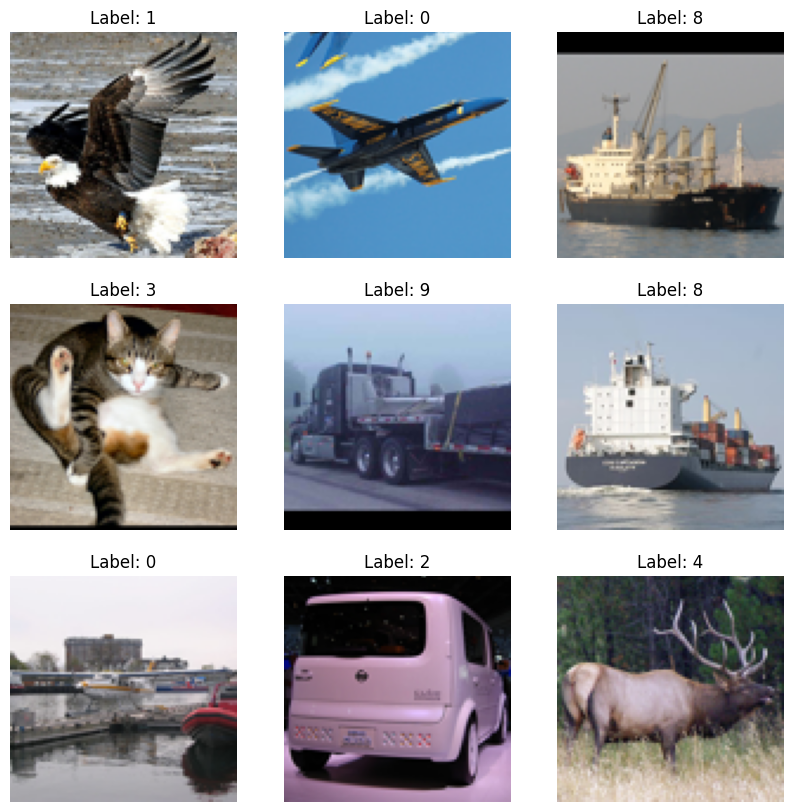

2026-03-14 18:57:16.532143: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
# Verify that the data is correct
import matplotlib.pyplot as plt
for images, labels in ds_train.take(1):
    print("Shape images:", images.shape)
    print("Shape labels:", labels.shape)
    print("Min/Max images:", tf.reduce_min(images), tf.reduce_max(images))
    print("Sample label:", labels[0])

# Visualize some images and their labels
for images, labels in ds_train.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Label: {tf.argmax(labels[i])}")
        plt.axis('off')
    plt.show()

In [ ]:
def preprocess_dogs_cats(image, label):
    image = tf.image.resize(image, (96, 96))
    label = tf.one_hot(label, depth=2)
    return image, label

ds_dogs_cats = ds_dogs_cats_train.map(preprocess_dogs_cats).batch(32).cache().prefetch(tf.data.AUTOTUNE)

print(ds_dogs_cats.element_spec)

(TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 2), dtype=tf.float32, name=None))


### **Experimento 1: Baseline**

To establish a baseline, a very simple convolutional architecture has been designed. First, the image pixels are scaled from their original range (0-255) to values between 0.0 and 1.0. Next, a single convolutional layer (Conv2D with 8 filters, a 3x3 kernel, and ReLU activation) is applied, which is responsible for feature extraction. The resulting value map is flattened and connected to the dense output layer with 10 neurons and Softmax activation for classification. The model is compiled using the Adam optimizer and the categorical crossentropy loss function, and is trained for 10 epochs.

In [ ]:
from tensorflow.keras.layers import Conv2D, Flatten, Dense, MaxPooling2D, Rescaling

inputs = keras.Input(shape=(96, 96, 3))
x = Rescaling(1./255)(inputs)
x = Conv2D(8, (3, 3), activation='relu')(x)
x = Flatten()(x)
outputs = Dense(10, activation='softmax')(x)

model1 = keras.Model(inputs=inputs, outputs=outputs)
model1.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

model1.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 94, 94, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 70688)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │       706,890 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 707,114 (2.70 MB)

 Trainable params: 707,114 (2.70 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
reset_seeds()
history1 = model1.fit(ds_train, validation_data=ds_val, epochs=10)


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2750 - loss: 2.8178 - val_accuracy: 0.3450 - val_loss: 1.7935
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5113 - loss: 1.4578 - val_accuracy: 0.3960 - val_loss: 1.6448
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7045 - loss: 1.0128 - val_accuracy: 0.4180 - val_loss: 1.6184
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8520 - loss: 0.6475 - val_accuracy: 0.4080 - val_loss: 1.6988
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9178 - loss: 0.4245 - val_accuracy: 0.3810 - val_loss: 1.8862
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9427 - loss: 0.3135 - val_accuracy: 0.3690 - val_loss: 2.1042
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9643 - loss: 0.2353 - val_accuracy: 0.3530 - val_loss: 2.3700
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9758 - loss: 0.1680 - val_accuracy: 0.

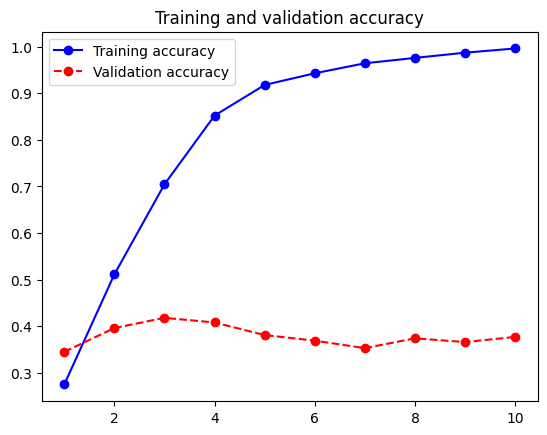

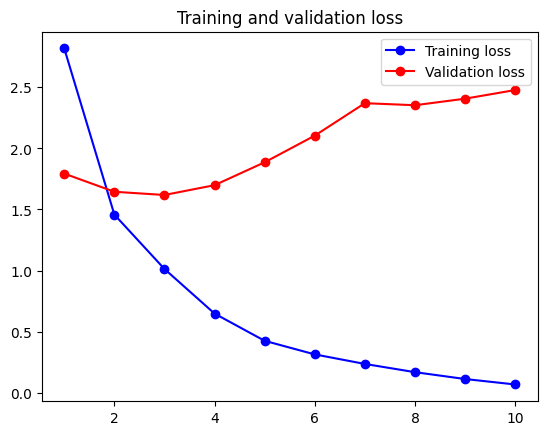

In [ ]:
plot(history1)

#### **Results**
After executing the training, the results show a clear case of overfitting. Since there is no Pooling layer to reduce dimensionality, the Flatten layer receives a large tensor that drastically increases the number of trainable parameters in the connection to the output layer. This makes it easier for the network to memorize the dataset.

From the fourth epoch onwards, the training accuracy exceeds 91%, finishing at epoch 10 with a nearly perfect accuracy of 99.60% and a minimal loss of 0.0672. Conversely, the performance on the validation set demonstrates that the model is unable to generalize. The validation accuracy quickly stagnates, peaking early at 41.80% in the third epoch and remaining around 37% by the end, without significant improvements. Furthermore, the validation loss, instead of decreasing, begins to progressively increase after the third epoch until reaching a high value of 2.4775 at the end of training.

Therefore, the base model has completely memorized the training set, losing its predictive capacity for unseen images. The need to introduce dimensionality reduction mechanisms like Pooling or regularization techniques in subsequent experiments to mitigate this overfitting is evident.

### **Experiment 2: Dimensionality Reduction (Pooling) and Deeper Architecture**

To mitigate the severe overfitting observed in the baseline model, a deeper architecture with dimensionality reduction mechanisms has been implemented. The single convolutional layer is replaced by a sequence of three convolutional blocks. Each block is composed of a Conv2D layer (with 8, 16, and 32 filters respectively, a 3x3 kernel, and ReLU activation) immediately followed by a MaxPooling2D (2x2) layer.

By introducing these pooling layers, the spatial dimensions of the feature maps are progressively reduced (from the initial 96x96 down to 10x10). Consequently, when the tensor is flattened (Flatten), the number of features passed to the final Dense layer is significantly smaller. As detailed in the model summary, the trainable parameters in the final connection have been drastically reduced (from 707,114 in the first experiment to just 38,042). The model is compiled and trained under the exact same conditions as the baseline (Adam optimizer, 10 epochs).

In [ ]:
from tensorflow.keras.layers import Conv2D, Flatten, Dense, MaxPooling2D

inputs = keras.Input(shape=(96, 96, 3))
x = Rescaling(1./255)(inputs)
x = Conv2D(8, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(16, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
outputs = Dense(10, activation='softmax')(x)

model2 = keras.Model(inputs=inputs, outputs=outputs)
model2.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

model2.summary()


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 94, 94, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 47, 47, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 45, 45, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 22, 22, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 20, 20, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 10, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        32,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,042 (148.60 KB)

 Trainable params: 38,042 (148.60 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
reset_seeds()
history2 = model2.fit(ds_train, validation_data=ds_val, epochs=10)


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3058 - loss: 1.9242 - val_accuracy: 0.3870 - val_loss: 1.6438
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4420 - loss: 1.5236 - val_accuracy: 0.4340 - val_loss: 1.5278
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4893 - loss: 1.3879 - val_accuracy: 0.4450 - val_loss: 1.4762
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5357 - loss: 1.2731 - val_accuracy: 0.4580 - val_loss: 1.4428
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5832 - loss: 1.1567 - val_accuracy: 0.4630 - val_loss: 1.4300
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6308 - loss: 1.0437 - val_accuracy: 0.4670 - val_loss: 1.4710
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6603 - loss: 0.9529 - val_accuracy: 0.4710 - val_loss: 1.5338
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6982 - loss: 0.8577 - val_accuracy: 0.

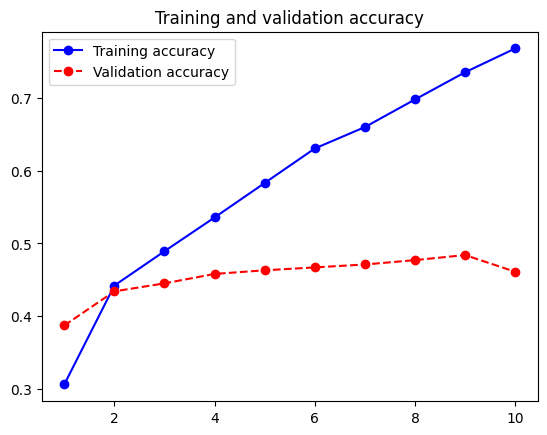

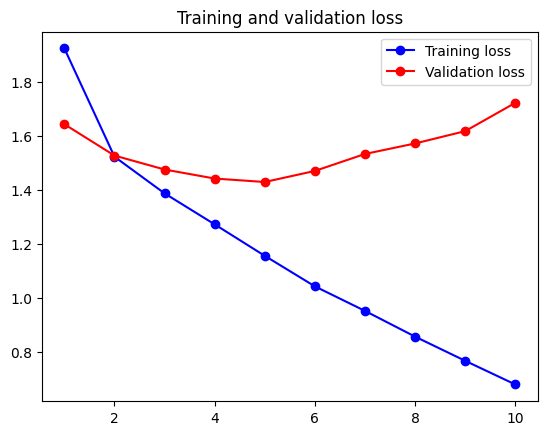

In [ ]:
plot(history2)

#### **Results**

Upon evaluating the results, a partial improvement in the network's generalization capacity is observed, although the fundamental issue of overfitting remains unresolved.

The reduction in trainable parameters successfully prevents the network from instantly memorizing the dataset. Instead of reaching a 99.6% accuracy, the training accuracy grows at a more controlled rate, finishing the 10th epoch at 76.85% with a loss of 0.6806. The validation accuracy reaches a maximum of 48.40%, this means an improvement over the previous 41.8%. Furthermore, the validation loss initially decreases, reaching its lowest point at epoch 5 (1.4300) before it begins to progressively increase again up to 1.7230.

The integration of MaxPooling2D layers and a deeper hierarchical feature extraction process has proven effective in reducing the model's complexity and slowing down the memorization process. However, the divergence between training and validation metrics from the fifth epoch onwards confirms that pooling alone is not sufficient to prevent overfitting. Therefore, before applying explicit regularization techniques, the next experiment will focus on improving the learning efficiency of the network by introducing a Normalization layer.

### Experiment 3: Input Data Normalization

Starting from the architecture of Experiment 2, this third experiment focuses on optimizing the input data flow. Instead of applying a standard rescaling, this step is entirely replaced by a Normalization layer adapted directly on the raw training dataset.

The objective of this layer is to apply a standardization (Z-score standardization) to the initial feature maps. By seeking to center the distribution of the input data, the aim is to improve the stability of the network and, consequently, the results.

In [ ]:
from tensorflow.keras.layers import Conv2D, Flatten, Dense, MaxPooling2D, Normalization

inputs = keras.Input(shape=(96, 96, 3))

norm_layer = Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(inputs)

x = Conv2D(8, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(16, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
outputs = Dense(10, activation='softmax')(x)

model3 = keras.Model(inputs=inputs, outputs=outputs)
model3.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

model3.summary()


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_5 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 94, 94, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 47, 47, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 45, 45, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 22, 22, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 20, 20, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 10, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │        32,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,049 (148.63 KB)

 Trainable params: 38,042 (148.60 KB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history3 = model3.fit(ds_train, validation_data=ds_val, epochs=10)


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.3190 - loss: 1.8740 - val_accuracy: 0.4220 - val_loss: 1.5818
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4918 - loss: 1.3986 - val_accuracy: 0.4820 - val_loss: 1.4018
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5723 - loss: 1.1876 - val_accuracy: 0.5070 - val_loss: 1.3692
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6407 - loss: 1.0196 - val_accuracy: 0.5080 - val_loss: 1.3765
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6967 - loss: 0.8630 - val_accuracy: 0.5200 - val_loss: 1.3835
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7620 - loss: 0.7112 - val_accuracy: 0.5140 - val_loss: 1.4694
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8105 - loss: 0.5902 - val_accuracy: 0.5150 - val_loss: 1.6308
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8450 - loss: 0.5087 - val_accuracy: 0.

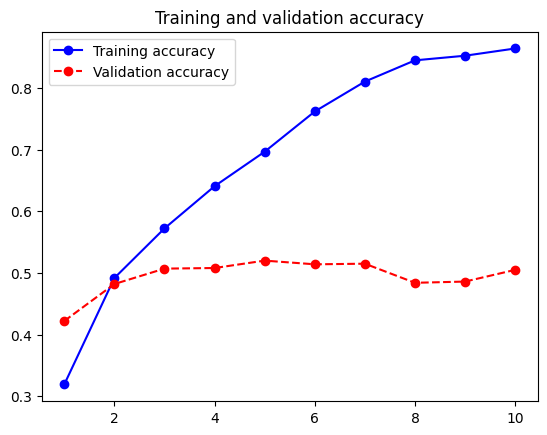

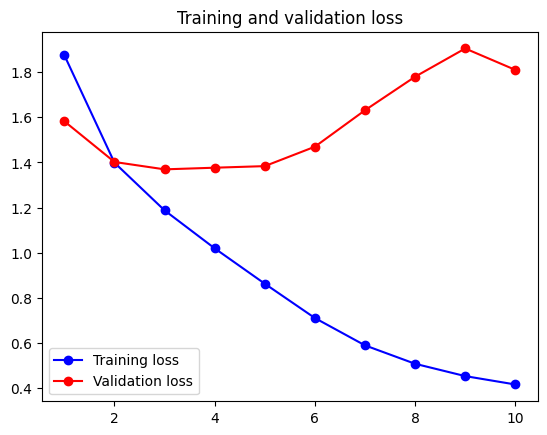

In [ ]:
plot(history3)

#### **Results**

After evaluating the training results, it is concluded that the inclusion of the Normalization layer has provided improvements in the stability and overall performance of the model.

The model exhibits a much faster learning pace compared to Experiment 2. The training accuracy grows rapidly, reaching 86.43% by the tenth epoch, with the loss dropping to 0.4171. The validation accuracy reaches a maximum peak of 51.20% in the eighth epoch (compared to 48.40% in the previous model). Furthermore, the validation loss decreases to a minimum of 1.3593 in the fifth period and, although it increases again later, it does so more gradually (closing at 1.5297) compared to the sharp rebound in the previous experiment.

The standardization of the data has fulfilled its purpose by providing greater stability to the network, which translates into a gain of nearly 4 percentage points in validation accuracy and a more contained error curve. However, from the fifth epoch onwards, the divergence between the training and validation curves becomes high once again. With the introduction of explicit regularization techniques, such as Dropout or Data Augmentation, we will seek to reinforce the generalization capacity of the network to improve the results.

### Experiment 4: Regularization with Dropout and Deeper Classifier

This experiment introduces in the fully connected section of the network (after the Flatten layer), an intermediate Dense layer with 64 neurons and ReLU activation is added to increase the model's representational capacity.

To prevent this newly added capacity from simply memorizing the data, two Dropout layers with a rate of 0.5 (50%) are placed before and after this new Dense layer. Due to this intentional handicap, the network requires more time to learn, so the training duration is extended from 10 to 20 epochs.

In [ ]:
from tensorflow.keras.layers import Conv2D, Flatten, Dense, MaxPooling2D, Normalization, Dropout

inputs = keras.Input(shape=(96, 96, 3))

norm_layer = Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(inputs)

x = Conv2D(8, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(16, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dropout(0.5)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)

model4 = keras.Model(inputs=inputs, outputs=outputs)

model4.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

model4.summary()


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_13                │ (None, 96, 96, 3)      │             7 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 94, 94, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 47, 47, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 45, 45, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 22, 22, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 20, 20, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 10, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,553 (826.38 KB)

 Trainable params: 211,546 (826.35 KB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history4 = model4.fit(ds_train, validation_data=ds_val, epochs=20)


Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.1928 - loss: 2.1264 - val_accuracy: 0.2990 - val_loss: 1.8040
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3063 - loss: 1.8167 - val_accuracy: 0.3820 - val_loss: 1.6249
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3355 - loss: 1.6968 - val_accuracy: 0.4090 - val_loss: 1.5524
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3800 - loss: 1.6003 - val_accuracy: 0.4330 - val_loss: 1.5158
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4085 - loss: 1.5487 - val_accuracy: 0.4480 - val_loss: 1.4650
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4275 - loss: 1.4668 - val_accuracy: 0.4490 - val_loss: 1.4452
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4593 - loss: 1.4177 - val_accuracy: 0.4720 - val_loss: 1.4035
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4837 - loss: 1.3694 - val_accuracy: 0.

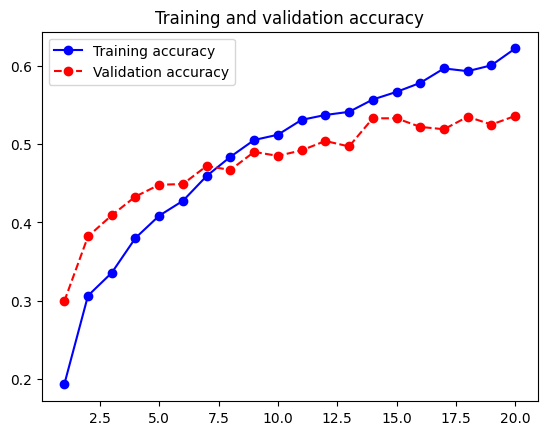

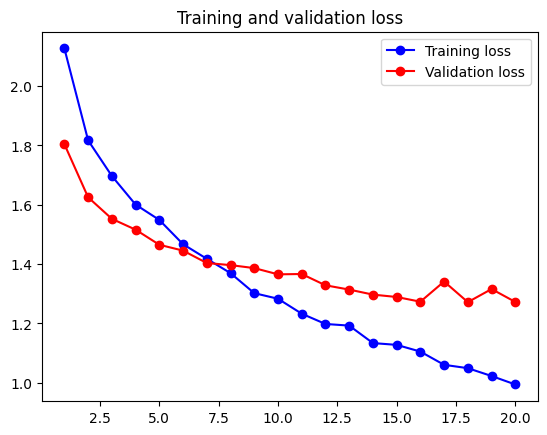

In [ ]:
plot(history4)

#### **Results**

After evaluating the training results, it is concluded that the inclusion of Dropout and the new Dense layer has reduced the overfitting problem.

As expected when applying aggressive regularization, the network is no longer able to instantly memorize the dataset. The training accuracy grows at a much slower and steadier pace, finishing the 20th epoch at 62.23% with a loss of 0.9941. This is a hard drop from the previous 86.43% training accuracy seen in Experiment 3. The validation accuracy grows consistently, reaching a peak of 53.60% by the final epoch and the shows a steadier downward trend, reaching a minimum of 1.2716 in the 18th epoch, eliminating the aggressive peaks of the previous experiments.

The introduction of Dropout has effectively acted as a strong regularizer. The huge gap between training and validation accuracy observed in Experiment 3 has been drastically reduced in this one. Having successfully stabilized the model and controlled the overfitting, the architecture is now ready to learn from a richer variety of examples. Therefore, the next experiment will implement Data Augmentation techniques to artificially expand the training dataset, exposing the network to spatial transformations to further push its generalization limits.

### Experiment 5: Data Augmentation and Increased Network Capacity

Starting from the architecture of Experiment 4, this phase addresses the limited size of the training dataset by implementing Data Augmentation techniques. At the very beginning of the pipeline, before normalization, three new layers are introduced: RandomFlip (horizontal), RandomRotation (10%), and RandomZoom (10%).  These layers artificially expand the dataset by applying random spatial transformations to the images during each training step, exposing the network to a much wider variety of scenarios and forcing it to learn orientation-invariant features.

To compensate for the increased complexity of the learning task, the representational capacity of the convolutional blocks is increased, upgrading the number of filters from 8-16-32 to 16-32-64. Most importantly, the training duration is significantly extended from 20 to 50 epochs. Because the network is constantly presented with modified, distorted versions of the images rather than the exact same pixels, the memorization process is completely disrupted, and the gradient descent requires a considerably longer time to converge on robust, generalizable patterns.

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Dropout, Normalization

inputs = Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.Conv2D(16, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = Flatten()(x)
x = Dropout(0.5)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)

model5 = keras.Model(inputs=inputs, outputs=outputs)

model5.compile(optimizer='adam', 
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model5.summary()

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_19 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_19              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_19 (RandomZoom)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_19                │ (None, 96, 96, 3)      │             7 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_186 (Conv2D)             │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_187 (Conv2D)             │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_188 (Conv2D)             │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_74 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 433,905 (1.66 MB)

 Trainable params: 433,898 (1.66 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history5 = model5.fit(ds_train, validation_data=ds_val, epochs=50)


Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.2100 - loss: 2.1417 - val_accuracy: 0.3190 - val_loss: 1.8544
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3167 - loss: 1.8629 - val_accuracy: 0.3760 - val_loss: 1.6560
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.3495 - loss: 1.7336 - val_accuracy: 0.4300 - val_loss: 1.5579
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.3808 - loss: 1.6531 - val_accuracy: 0.4600 - val_loss: 1.4583
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.3965 - loss: 1.5769 - val_accuracy: 0.4440 - val_loss: 1.4789
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4195 - loss: 1.5475 - val_accuracy: 0.4640 - val_loss: 1.4648
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4263 - loss: 1.5089 - val_accuracy: 0.4670 - val_loss: 1.4059
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4512 - loss: 1.4668 - val_accu

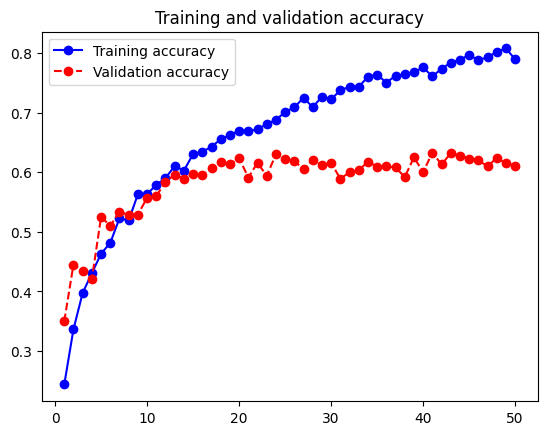

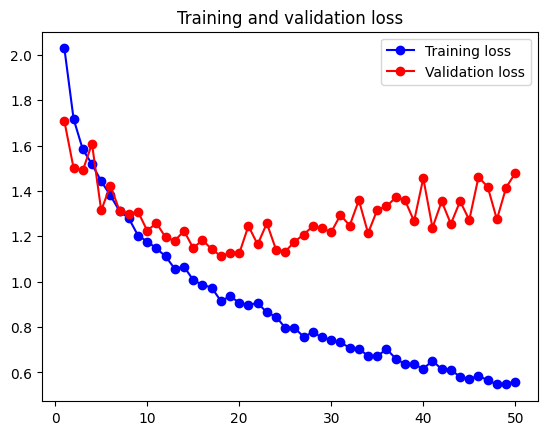

In [ ]:
plot(history5)

#### **Results**

After evaluating the training logs, it is concluded that the combination of Data Augmentation and Dropout has completely eradicated the overfitting problem, resulting in the most robust and best generalizing model developed by the moment.

As a direct consequence of the continuous regulation, the network finds it difficult to memorize the training set. The accuracy grows at a very slow and stable pace, finishing the 50th epoch at 62.48% with a loss of 1.0187. This is identical to the final training accuracy of Experiment 4, but achieved over a much longer period. Generalization has improved, resulting in a new overall peak of 62.40% in the 46th epoch (closing at 60.70%). Furthermore, the validation loss (val_loss) establishes a solid downward trend throughout the extended training period, hitting a new historical minimum of 1.1086 (also at epoch 46).

The synergy between Data Augmentation, Dropout, and direct Normalization has proven highly effective. The performance gap between the training and validation sets has been reduced, demonstrating that the model is no longer memorizing, but truly learning generalizable features. Having successfully built and optimized a robust custom architecture that maximizes the potential of a small dataset, the next step is to explore alternative stabilization techniques. Specifically, the following experiment will introduce Batch Normalization to determine whether the network's internal flow can be further optimized to push these generalization limits even higher.

### Experiment 6

Building upon the architecture established in Experiment 5, this phase investigates the impact of Batch Normalization. To test it, a Batch Normalization layer is introduced immediately after the first convolutional operation, prior to the ReLU activation function. By centering and scaling the data of each batch, the objective is to ensure a smooth and controlled flow of information between layers, which could accelerate the learning process and improve the results.

In [ ]:
from keras import layers

inputs = keras.Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

norm_layer = layers.Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.Conv2D(16, (3, 3))(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3))(x)
# x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3))(x)
# x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model6 = keras.Model(inputs=inputs, outputs=outputs)

model6.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model6.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 94, 94, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 94, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,662,769 (6.34 MB)

 Trainable params: 1,662,730 (6.34 MB)

 Non-trainable params: 39 (160.00 B)

In [ ]:
reset_seeds()
history6 = model6.fit(ds_train, validation_data=ds_val, epochs=50)


Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.2010 - loss: 2.2152 - val_accuracy: 0.2120 - val_loss: 2.0581
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.2722 - loss: 1.9635 - val_accuracy: 0.3300 - val_loss: 1.8271
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3122 - loss: 1.7990 - val_accuracy: 0.4100 - val_loss: 1.6344
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3473 - loss: 1.7528 - val_accuracy: 0.3900 - val_loss: 1.6737
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.3568 - loss: 1.6826 - val_accuracy: 0.3990 - val_loss: 1.7284
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.3677 - loss: 1.6255 - val_accuracy: 0.4010 - val_loss: 1.8796
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3970 - loss: 1.6133 - val_accuracy: 0.4390 - val_loss: 1.6453
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3997 - loss: 1.5632 - val_accu

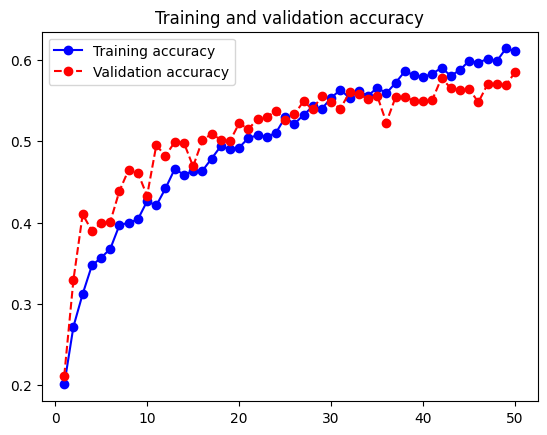

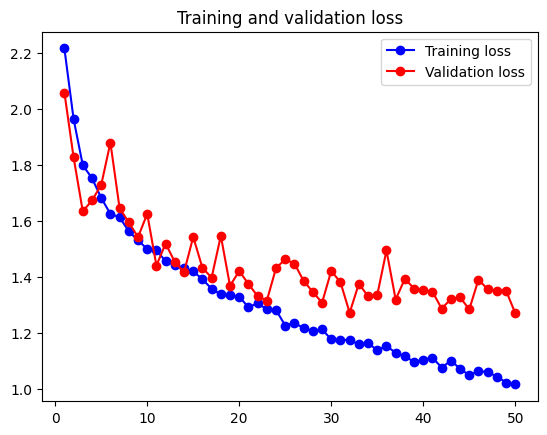

In [ ]:
plot(history6)

Upon evaluating the results, it is observed that the addition of Batch Normalization does not yield the expected improvements. Instead of boosting performance, it slightly degrades the model's overall generalization capacity compared to the previous benchmark.

The network maintains a steady learning pace, finishing the 50th epoch with a training accuracy of 61.08% and a loss of 1.0173. These metrics are almost identical to those seen in Experiment 5. However, the generalization capacity has deteriorated, as the validation accuracy plateaus earlier, peaking at a maximum of 58.50% (compared to the 62.40% achieved previously). Furthermore, the validation loss shows higher variance and closes at 1.2712, failing to reach the much lower 1.1086 minimum established by the previous model.

It should be noted that during this phase, a number of structural configurations were tested in order to understand this drop in performance. Initially, BatchNormalization layers were applied after every convolutional block. However, this configuration significantly worsened the results. This is highly likely due to a phenomenon of excessive regularization. Because Batch Normalization inherently introduces noise to the batches, combining it with the Data Augmentation and the dropout overloaded the network, preventing it from learning meaningful patterns. To counteract this excessive regularization, alternative tests were conducted where the Dropout layers were removed to allow the network to rely solely on Batch Normalization and Data Augmentation. However, this configuration yielded slightly worse results, ultimately failing to achieve the objective of surpassing the best validation metrics established in the previous experiment.

So the architecture defined in Experiment 5 remains the most optimal custom configuration for this dataset. Having ruled out Batch Normalization for this specific architecture, the next experiment will pivot to a different regularization strategy, that is to apply SpatialDropout2D directly to the feature maps.

### Experiment 7: Spatial Dropout

Starting from the findings of Experiment 6, this phase replaces Batch Normalization with SpatialDropout2D (0.1-0.2-0.3) to test a different regularization strategy. Unlike standard Dropout, which randomly disables individual activations, Spatial Dropout drops entire feature maps. This prevents the network from recovering missing information by relying on highly correlated adjacent pixels, forcing it to learn more independent and robust visual features.

To compensate for this aggressive penalty, the representational capacity of the network is significantly increased: the convolutional filters are upgraded to 32-64-128, and the intermediate dense layer is expanded to 128 neurons. The model is trained for 60 epochs to allow the model enough time to converge under these stricter regularization conditions.

In [ ]:
from tensorflow import keras
from keras import layers

inputs = keras.Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = layers.Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.Conv2D(32, (3, 3))(x)
x = layers.Activation("relu")(x)
x = layers.SpatialDropout2D(0.1)(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3))(x)
x = layers.Activation("relu")(x)
x = layers.SpatialDropout2D(0.2)(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3))(x)
x = layers.Activation("relu")(x)
x = layers.SpatialDropout2D(0.3)(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model7 = keras.Model(inputs=inputs, outputs=outputs)

model7.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model7.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_12 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_12              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_12 (RandomZoom)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_7 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_27 (Activation)      │ (None, 94, 94, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_21            │ (None, 94, 94, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_28 (Activation)      │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_22            │ (None, 45, 45, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_29 (Activation)      │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_23            │ (None, 20, 20, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,733,073 (6.61 MB)

 Trainable params: 1,733,066 (6.61 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history7 = model7.fit(ds_train, validation_data=ds_val, epochs=60)

Epoch 1/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.1960 - loss: 2.1466 - val_accuracy: 0.3240 - val_loss: 1.8706
Epoch 2/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.2835 - loss: 1.8752 - val_accuracy: 0.3980 - val_loss: 1.5906
Epoch 3/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.3417 - loss: 1.7491 - val_accuracy: 0.4430 - val_loss: 1.5613
Epoch 4/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.3643 - loss: 1.6846 - val_accuracy: 0.4580 - val_loss: 1.4935
Epoch 5/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.3772 - loss: 1.6463 - val_accuracy: 0.4190 - val_loss: 1.5762
Epoch 6/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.4017 - loss: 1.6060 - val_accuracy: 0.4540 - val_loss: 1.5079
Epoch 7/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.4182 - loss: 1.5624 - val_accuracy: 0.4710 - val_loss: 1.4177
Epoch 8/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.4155 - loss: 1.5588 - val_accu

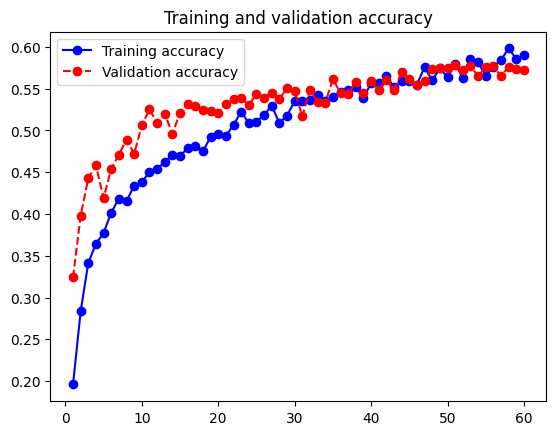

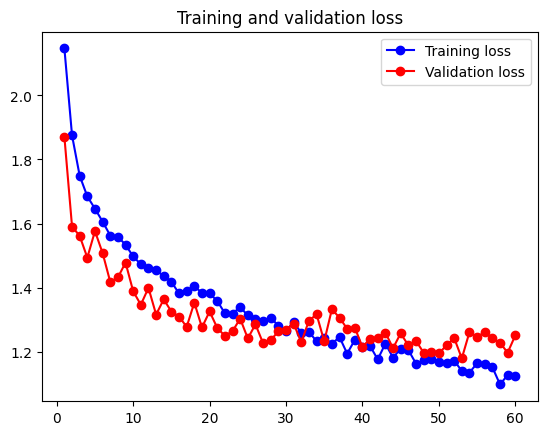

In [ ]:
plot(history7)

#### **Results**

After evaluating the training logs, it is concluded that the implementation of Spatial Dropout also fails to exceed the maximum accuracy achieved in Experiment 5.

Prior to establishing the final architecture, several structural configurations were evaluated, including a constant rate across all blocks, a more aggressive ones, and even the use of spatial dropout only in the deepest layers. The results showed that a progressive dropout approach offered the best balance.

As a result of dropping feature maps, the network learns at a very controlled pace. The training accuracy slowly progresses to 59.05% by the 60th epoch, with a loss of 1.1252. The validation metrics closely follow this steady progression. The validation accuracy reaches a peak of 57.80% in epoch 51, while the validation loss establishes a correct downward trend, hitting a minimum of 1.1789 in epoch 53.

Although the architecture has proven to be exceptionally robust, the maximum overall accuracy remains slightly below the 62.40% achieved previously. Having exhausted standard regularization adjustments on this basic sequential structure, the next experiment will explore deeper architectural patterns. Specifically, the following phase will stack multiple convolutional layers consecutively before applying pooling operations, drawing inspiration from VGG-style architectures to extract deeper hierarchical features.

### Experiment 8: VGG Style Stacking

Moving away from the previous experiment, this one investigates the impact of network depth based on the VGG architectural philosophy. The core principle involves stacking multiple consecutive convolutional layers before applying any spatial reduction. This strategy implies two main structural changes in how the network processes the data. First, stacking convolutional layers together expands the effective receptive field, allowing the network to evaluate a larger spatial context of the image without increasing the filter size. Second, passing the data sequentially through multiple non-linear activation functions (relu) forces the model to build more complex representations of the visual patterns before the spatial resolution is reduced by the pooling layer.

In [ ]:
from tensorflow.keras.layers import Input

inputs = Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = layers.Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.Conv2D(16, (3, 3), activation='relu')(x)
x = layers.Conv2D(16, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model8 = keras.Model(inputs=inputs, outputs=outputs)

model8.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model8.summary()

Model: "functional_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_25 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_25              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_25 (RandomZoom)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_25                │ (None, 96, 96, 3)      │             7 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_253 (Conv2D)             │ (None, 94, 94, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_254 (Conv2D)             │ (None, 92, 92, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_106               │ (None, 46, 46, 16)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_255 (Conv2D)             │ (None, 44, 44, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_256 (Conv2D)             │ (None, 42, 42, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_107               │ (None, 21, 21, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_257 (Conv2D)             │ (None, 19, 19, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_258 (Conv2D)             │ (None, 17, 17, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_108               │ (None, 8, 8, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_20 (Flatten)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 334,945 (1.28 MB)

 Trainable params: 334,938 (1.28 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history8 = model8.fit(ds_train, validation_data=ds_val, epochs=60)


Epoch 1/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.1510 - loss: 2.2285 - val_accuracy: 0.2450 - val_loss: 2.0204
Epoch 2/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2550 - loss: 1.9835 - val_accuracy: 0.2870 - val_loss: 1.9640
Epoch 3/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2975 - loss: 1.8213 - val_accuracy: 0.3230 - val_loss: 1.8610
Epoch 4/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.3215 - loss: 1.7485 - val_accuracy: 0.3290 - val_loss: 1.8684
Epoch 5/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.3315 - loss: 1.6866 - val_accuracy: 0.3490 - val_loss: 1.7338
Epoch 6/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.3490 - loss: 1.6558 - val_accuracy: 0.3840 - val_loss: 1.5749
Epoch 7/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.3658 - loss: 1.6218 - val_accuracy: 0.3780 - val_loss: 1.7276
Epoch 8/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.3885 - loss: 1.5784 - val_accu

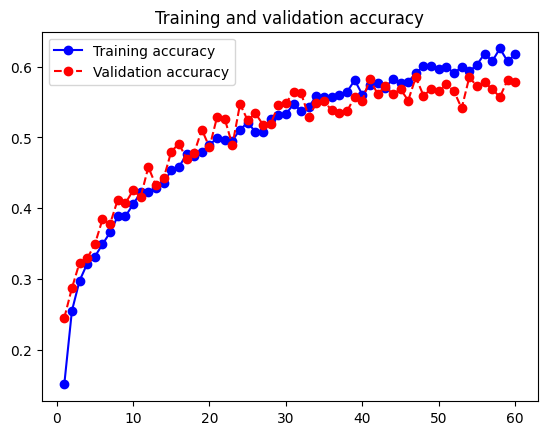

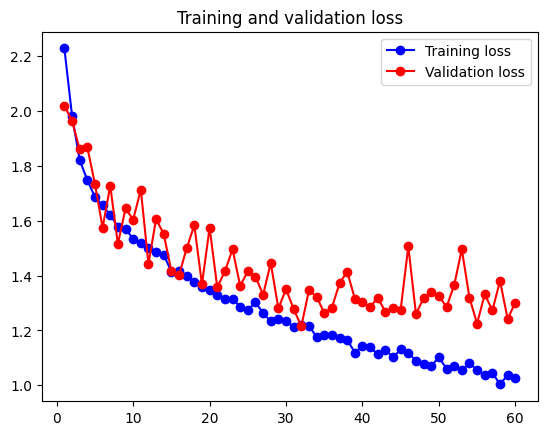

In [ ]:
plot(history8)

#### **Results**

To determine the optimal layer distribution, multiple stacking configurations were tested across the three convolutional blocks. These configurations ranged from a baseline (1-1-1) and a progressive deepening approach (1-2-3), to aggressively deep setups (2-3-3). The results indicated that a uniform depth distribution, the 2-2-2 configuration, yielded the highest validation accuracy (62.1%) during this testing phase.

An evaluation of the training logs reveals that while the VGG-style stacking should create a highly capable feature extractor, the architecture appears to be reaching the absolute performance ceiling for standard sequential models on this dataset.

The model achieves a training accuracy of 61.73% by the 60th epoch and peaking at 62.55% in epoch 58. The training loss maintains a smooth downward trajectory, closing at 1.0249. Generalization tracks the training progress relatively well, although it plateaus earlier than desired. The validation accuracy remains consistently around 56–58% during the second half of the training period, peaking at 58.50% in epoch 54, and the lowest value for the loss is 1.2150 in the epoch 32.

Despite the theoretical advantages of stacked convolutions, the model struggles to surpass the validation threshold of 62% established in previous experiments. This suggests that adding more sequential layers does not yield significant benefits and may be causing a slight loss of gradients. To decisively overcome this ceiling, the architecture must evolve beyond linear and sequential stacking. Therefore, the next experiment will introduce residual networks, implementing skip connections to allow gradients to flow freely through deeper blocks.

### Experiment 9: Residual Network

This experiment introduces the core concept of Residual Networks. The architecture incorporates skip connections (shortcuts) that bypass the main convolutional operations. Instead of forcing the network to learn completely new representations at every step, these connections allow the network to learn only the residual changes and add them to the original input. This ensures that if a layer fails to learn anything useful, the original information still flows forward intact, effectively mitigating the vanishing gradient problem and allowing for much deeper feature extraction.

In [ ]:
from keras import layers
def residual_block(x, filters, kernel_size=3):
    shortcut = x
    
    # Si el número de canales cambia, proyectar el shortcut
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, padding="same")(shortcut)

    x= layers.Conv2D(filters, kernel_size, padding="same")(x)
    x= layers.Activation("relu")(x)

    x = layers.Conv2D(filters, kernel_size, padding="same")(x)
    x= layers.Add()([x,shortcut])
    x = layers.Activation("relu")(x)
    return x

In [ ]:
inputs = keras.Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = layers.Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = residual_block(x, filters=16)
x = layers.MaxPooling2D(2)(x)

x = residual_block(x, filters=32)
x = layers.MaxPooling2D(2)(x)

x = residual_block(x, filters=64)
x = layers.MaxPooling2D(2)(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model9 = keras.Model(inputs=inputs, outputs=outputs)

model9.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model9.summary()

2026-03-14 19:21:27.185803: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_5       │ (None, 96, 96, 3) │          0 │ input_layer_5[0]… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_5   │ (None, 96, 96, 3) │          0 │ random_flip_5[0]… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_5       │ (None, 96, 96, 3) │          0 │ random_rotation_… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_5     │ (None, 96, 96, 3) │          7 │ random_zoom_5[0]… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 96, 96,    │        448 │ normalization_5[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 96, 96,    │          0 │ conv2d_28[0][0]   │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 96, 96,    │      2,320 │ activation_9[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 96, 96,    │         64 │ normalization_5[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 96, 96,    │          0 │ conv2d_29[0][0],  │
│                     │ 16)               │            │ conv2d_27[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 96, 96,    │          0 │ add_9[0][0]       │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 48, 48,    │          0 │ activation_10[0]… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 48, 48,    │      4,640 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 48, 48,    │          0 │ conv2d_31[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 48, 48,    │      9,248 │ activation_11[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 48, 48,    │        544 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 48, 48,    │          0 │ conv2d_32[0][0],

 Total params: 665,345 (2.54 MB)

 Trainable params: 665,338 (2.54 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()
history9 = model9.fit(ds_train, validation_data=ds_val, epochs=60)


Epoch 1/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.1975 - loss: 2.1759 - val_accuracy: 0.2860 - val_loss: 1.9245
Epoch 2/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.2905 - loss: 1.9160 - val_accuracy: 0.4040 - val_loss: 1.6641
Epoch 3/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.3318 - loss: 1.7583 - val_accuracy: 0.4380 - val_loss: 1.5208
Epoch 4/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.3618 - loss: 1.6757 - val_accuracy: 0.3960 - val_loss: 1.6039
Epoch 5/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.3877 - loss: 1.6015 - val_accuracy: 0.4400 - val_loss: 1.5118
Epoch 6/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.4060 - loss: 1.5558 - val_accuracy: 0.4410 - val_loss: 1.5142
Epoch 7/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.4193 - loss: 1.5136 - val_accuracy: 0.4630 - val_loss: 1.4545
Epoch 8/60
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.4390 - loss: 1.4798 - val_accu

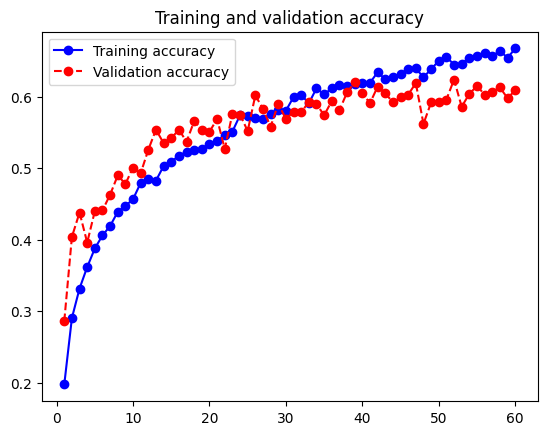

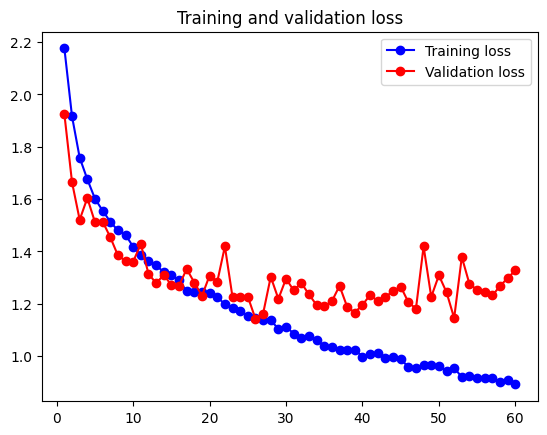

In [ ]:
plot(history9)

#### **Results**

Initially, a GlobalAveragePooling2D layer was tested to replace the standard Flatten operation, following modern ResNet designs. However, empirical results showed a big drop in performance. The reason lies in how spatial information is handled. GlobalAveragePooling2D calculates a single average value for each entire 2D feature map, completely discarding the spatial layout. While this works well in very deep models where final layers encode purely abstract concepts, our custom architecture is relatively shallow. While this works well in very deep models where final layers encode purely abstract concepts, our custom architecture is relatively shallow. Therefore, destroying these spatial details prevented the model from properly recognizing complex visual patterns. Consequently, the architecture was reverted to the Flatten approach, using MaxPooling2D after each residual block to reduce the image size step by step.

Checking the the training results, it can be seen that the implementation of residual blocks successfully restored the network's learning capacity, though it highlights the absolute generalization limits of training from scratch on this dataset.

The skip connections allow the model to learn at a steady pace, reaching an accuracy of 66.75% by the 60th epoch, with the training loss steadily dropping to 0.8909. The validation accuracy peaks at 62.40% in epoch 52, while the validation loss reaches its lowest point of 1.1420 much earlier (epoch 26) before gradually rising.

Despite the complex feature extraction enabled by the residual blocks and the robust regularization, the validation accuracy once again fails to exceed the 62% threshold we had previously achieved. Furthermore, while this architecture matches our previous best performance, it does so at a significantly higher computational cost. The added complexity of the residual paths increases training time and resource consumption without providing a proportional gain in generalization. To definitively break this performance ceiling, the architecture must evolve to capture visual patterns at multiple spatial scales simultaneously. Therefore, the next experiment will explore the Inception architecture.

### Experiment 10: Inception Architecture

This experiment introduces the core concept of the Inception architecture. Instead of forcing the network to process images sequentially through a single fixed filter size, Inception modules process the input through multiple parallel convolutional paths (such as 1x1, 3x3, and 5x5 filters) alongside a pooling layer within the same block. This approach allows the network to capture both fine local details and broader spatial structures simultaneously, maximizing feature extraction efficiency without deepening the network unnecessarily.

In [ ]:
kernel_init = "glorot_uniform"
bias_init = "zeros"

def inception_module(x, filters_1x1, filters_3x3_reduce, filters_3x3, filters_5x5_reduce,
                     filters_5x5, filters_pool_proj, name=None):
    
    # 1×1 route
    conv_1x1 = layers.Conv2D(filters_1x1, kernel_size=(1, 1), padding='same', activation='relu',
               kernel_initializer=kernel_init, bias_initializer=bias_init)(x)
 
    # 3×3 route = 1×1 CONV + 3×3 CONV 
    pre_conv_3x3 = layers.Conv2D(filters_3x3_reduce, kernel_size=(1, 1), padding='same',
                   activation='relu', kernel_initializer=kernel_init, 
                   bias_initializer=bias_init)(x)
    
    conv_3x3 = layers.Conv2D(filters_3x3, kernel_size=(3, 3), padding='same', activation='relu', 
               kernel_initializer=kernel_init, 
               bias_initializer=bias_init)(pre_conv_3x3)
      
    # 5×5 route = 1×1 CONV + 5×5 CONV 
    pre_conv_5x5 = layers.Conv2D(filters_5x5_reduce, kernel_size=(1, 1), padding='same',
                   activation='relu', kernel_initializer=kernel_init, 
                   bias_initializer=bias_init)(x)
    
    conv_5x5 = layers.Conv2D(filters_5x5, kernel_size=(5, 5), padding='same', activation='relu', 
                  kernel_initializer=kernel_init, 
                  bias_initializer=bias_init)(pre_conv_5x5)
    
    # pool route = POOL + 1×1 CONV 
    pool_proj = layers.MaxPool2D((3, 3), strides=(1, 1), padding='same')(x)
    pool_proj = layers.Conv2D(filters_pool_proj, (1, 1), padding='same', activation='relu',
                  kernel_initializer=kernel_init, bias_initializer=bias_init)(pool_proj)
 
    # final concatenation
    output = layers.concatenate([conv_1x1, conv_3x3, conv_5x5, pool_proj], axis=3,  name=name)
 
    return output

In [ ]:
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom, Normalization

inputs = Input(shape=(96, 96, 3))

# Data augmentation
x = RandomFlip("horizontal", seed=seed)(inputs)
x = RandomRotation(0.1, seed=seed)(x)
x = RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = Conv2D(32, (3, 3), padding="same", activation='relu')(x)
x = MaxPooling2D((2, 2))(x)

inception_1 = inception_module(x, filters_1x1=64, filters_3x3_reduce=32,
                     filters_3x3=64, filters_5x5_reduce=16,
                     filters_5x5=64, filters_pool_proj=32)
x = MaxPooling2D((2, 2))(inception_1)

inception_2 = inception_module(x, filters_1x1=64, filters_3x3_reduce=32,
                     filters_3x3=128, filters_5x5_reduce=16,
                     filters_5x5=64, filters_pool_proj=64)
x = MaxPooling2D((2, 2))(inception_2)

inception_3 = inception_module(x, filters_1x1=128, filters_3x3_reduce=64,
                     filters_3x3=256, filters_5x5_reduce=32,
                     filters_5x5=128, filters_pool_proj=128)
x = MaxPooling2D((2, 2))(inception_3)

x = Flatten()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)

model10 = keras.Model(inputs=inputs, outputs=outputs)

model10.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model10.summary()

Model: "functional_21"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_23      │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_23      │ (None, 96, 96, 3) │          0 │ input_layer_23[0… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_23  │ (None, 96, 96, 3) │          0 │ random_flip_23[0… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_23      │ (None, 96, 96, 3) │          0 │ random_rotation_… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_23    │ (None, 96, 96, 3) │          7 │ random_zoom_23[0… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_234 (Conv2D) │ (None, 96, 96,    │        896 │ normalization_23… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_92    │ (None, 48, 48,    │          0 │ conv2d_234[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_236 (Conv2D) │ (None, 48, 48,    │      1,056 │ max_pooling2d_92… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_238 (Conv2D) │ (None, 48, 48,    │        528 │ max_pooling2d_92… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_93    │ (None, 48, 48,    │          0 │ max_pooling2d_92… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_235 (Conv2D) │ (None, 48, 48,    │      2,112 │ max_pooling2d_92… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_237 (Conv2D) │ (None, 48, 48,    │     18,496 │ conv2d_236[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_239 (Conv2D) │ (None, 48, 48,    │     25,664 │ conv2d_238[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_240 (Conv2D) │ (None, 48, 48,    │      1,056 │ max_pooling2d_93… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_17      │ (None, 48, 48,    │          0 │ conv2d_235[0][0], │
│ (Concatenate)       │ 224)              │            │ conv2d_237[0][0], │
│                     │                   │            │ conv2d_239[0][0], │
│                     │                   │            │ conv2d_240[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_94    │ (None, 24, 24,    │          0 │ concatenate_17[0… │
│ (MaxPooling2D)      │ 224)              │            │                 

 Total params: 3,465,841 (13.22 MB)

 Trainable params: 3,465,834 (13.22 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history10 = model10.fit(ds_train, validation_data=ds_val,
                    epochs=50, callbacks=[early_stopping, reduce_lr])

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.2508 - loss: 2.0069 - val_accuracy: 0.3570 - val_loss: 1.7612 - learning_rate: 0.0010
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 126ms/step - accuracy: 0.3632 - loss: 1.6509 - val_accuracy: 0.4610 - val_loss: 1.5000 - learning_rate: 0.0010
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step - accuracy: 0.4322 - loss: 1.5046 - val_accuracy: 0.4550 - val_loss: 1.5075 - learning_rate: 0.0010
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step - accuracy: 0.4507 - loss: 1.4489 - val_accuracy: 0.4500 - val_loss: 1.5361 - learning_rate: 0.0010
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 132ms/step - accuracy: 0.4920 - loss: 1.3647 - val_accuracy: 0.5250 - val_loss: 1.2938 - learning_rate: 0.0010
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step - accuracy: 0.5135 - loss: 1.3051 - val_accuracy: 0.5160 - val_loss: 1.3605 - learning_rate: 0.0010
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 128ms/step - accuracy: 0.5

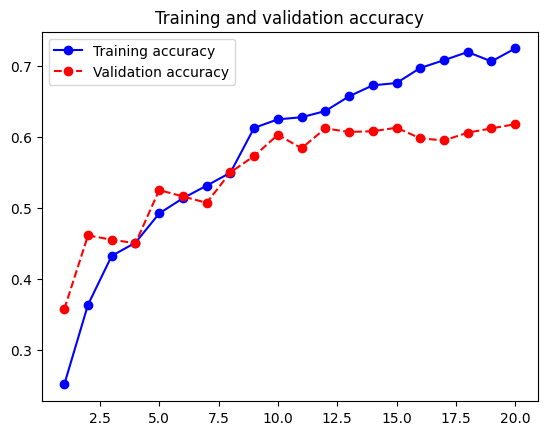

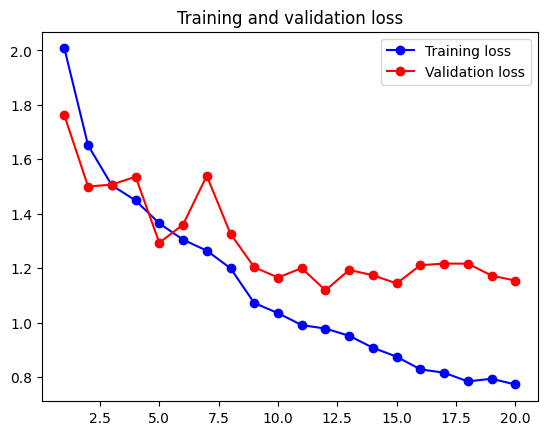

In [ ]:
plot(history10)

#### **Results**

Several architectural variations were evaluated to find the optimal balance. To maintain a fair baseline comparable to our previous models, a balanced 3-block design was selected, preceded by a standard convolutional stem to process the raw pixels, and concluding with our proven Flatten and Dense approach. Additionally, starting from this experiment, EarlyStopping and ReduceLROnPlateau callbacks have been permanently introduced to agilely optimize the training process. These ensure the model makes finer weight updates as it approaches a minimum and automatically halts training when generalization ceases, saving computational time.

Checking the training logs, the model learns rapidly, reaching a training accuracy of 72.47% by the 20th epoch, with the training loss dropping to 0.7735. The ReduceLROnPlateau callback triggers successfully multiple times, dynamically reducing the learning rate from 0.001 to 0.000027 to help the model fine-tune its weights. However, despite these advanced parallel feature extractors and precise learning rate adjustments, the validation accuracy once again hits a hard ceiling around 61.80%. The validation loss reaches its minimum of 1.1189 much earlier in the training (epoch 12) before beginning to stagnate and slightly bounce, signaling the beginning of overfitting despite the robust dropout layers.

The consistent plateau across sequential models, residual networks, and now parallel multi-scale architectures definitively proves that the limitation is no longer the model design, but the dataset itself. Nevertheless, as a final experiment, the basic principle of the Xception architecture will be incorporated.

### Experiment 11: Xception Architecture

The standard convolutions with a large number of parameters in the Inception modules were replaced by deep separable convolutions (SeparableConv2D). This approach separates spatial filtering (shape detection) from point-wise filtering (channel mixing). The aim is to drastically reduce the number of mathematical operations and parameters, in order to delay overfitting and to test whether a highly efficient use of parameters can finally break through the persistent validation ceiling.

In [ ]:
kernel_init = "glorot_uniform"
bias_init = "zeros"

def inception_module_separable(x, filters_1x1, filters_3x3_reduce, filters_3x3, filters_5x5_reduce,
                     filters_5x5, filters_pool_proj, name=None):

    # 1×1 route
    conv_1x1 = layers.SeparableConv2D(filters_1x1, kernel_size=(1, 1), padding='same',
                             depthwise_initializer=kernel_init, pointwise_initializer=kernel_init,
                             bias_initializer=bias_init)(x)
    conv_1x1 = layers.Activation("relu")(conv_1x1)

    # 3×3 route = 1×1 CONV + 3×3 CONV
    pre_conv_3x3 = layers.SeparableConv2D(filters_3x3_reduce, kernel_size=(1, 1), padding='same',
                                 depthwise_initializer=kernel_init,
                                 bias_initializer=bias_init, pointwise_initializer=kernel_init)(x)

    conv_3x3 = layers.SeparableConv2D(filters_3x3, kernel_size=(3, 3), padding='same',
                             depthwise_initializer=kernel_init, pointwise_initializer=kernel_init,
                             bias_initializer=bias_init)(pre_conv_3x3)
    conv_3x3 = layers.Activation("relu")(conv_3x3)

    # 5×5 route = 1×1 CONV + 5×5 CONV
    pre_conv_5x5 = layers.SeparableConv2D(filters_5x5_reduce, kernel_size=(1, 1), padding='same',
                                depthwise_initializer=kernel_init,
                                 bias_initializer=bias_init, pointwise_initializer=kernel_init)(x)

    conv_5x5 = layers.SeparableConv2D(filters_5x5, kernel_size=(5, 5), padding='same',
                             depthwise_initializer=kernel_init, pointwise_initializer=kernel_init,
                             bias_initializer=bias_init)(pre_conv_5x5)
    
    conv_5x5 = layers.Activation("relu")(conv_5x5)

    # pool route = POOL + 1×1 CONV
    pool_proj = layers.MaxPool2D((3, 3), strides=(1, 1), padding='same')(x)
    pool_proj = layers.SeparableConv2D(filters_pool_proj, (1, 1), padding='same',
                              depthwise_initializer=kernel_init, pointwise_initializer=kernel_init, bias_initializer=bias_init)(pool_proj)

    pool_proj = layers.Activation("relu")(pool_proj)

    # final concatenation
    output = layers.concatenate([conv_1x1, conv_3x3, conv_5x5,
                                 pool_proj], axis=3,  name=name)

    return output

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = layers.Input(shape=(96, 96, 3))

# Data augmentation
x = layers.RandomFlip("horizontal", seed=seed)(inputs)
x = layers.RandomRotation(0.1, seed=seed)(x)
x = layers.RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = layers.Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.SeparableConv2D(32, (3, 3), padding="same", activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)


inception_1 = inception_module_separable(x, filters_1x1=64, filters_3x3_reduce=32,
                     filters_3x3=64, filters_5x5_reduce=16,
                     filters_5x5=64, filters_pool_proj=32)
x = layers.MaxPooling2D((2, 2))(inception_1)

inception_2 = inception_module_separable(x, filters_1x1=64, filters_3x3_reduce=32,
                     filters_3x3=128, filters_5x5_reduce=16,
                     filters_5x5=64, filters_pool_proj=64)
x = layers.MaxPooling2D((2, 2))(inception_2)

inception_3 = inception_module_separable(x, filters_1x1=128, filters_3x3_reduce=64,
                     filters_3x3=256, filters_5x5_reduce=32,
                     filters_5x5=128, filters_pool_proj=128)
x = layers.MaxPooling2D((2, 2))(inception_3)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model11 = keras.Model(inputs=inputs, outputs=outputs)

optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model11.compile(optimizer=optimizer,
                loss='categorical_crossentropy',
                metrics=['accuracy'])

model11.summary()


Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_31      │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_31      │ (None, 96, 96, 3) │          0 │ input_layer_31[0… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_31  │ (None, 96, 96, 3) │          0 │ random_flip_31[0… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_31      │ (None, 96, 96, 3) │          0 │ random_rotation_… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_30    │ (None, 96, 96, 3) │          7 │ random_zoom_31[0… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_86 │ (None, 96, 96,    │        155 │ normalization_30… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_135   │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_88 │ (None, 48, 48,    │      1,088 │ max_pooling2d_13… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_90 │ (None, 48, 48,    │        560 │ max_pooling2d_13… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_136   │ (None, 48, 48,    │          0 │ max_pooling2d_13… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_87 │ (None, 48, 48,    │      2,144 │ max_pooling2d_13… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_89 │ (None, 48, 48,    │      2,400 │ separable_conv2d… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_91 │ (None, 48, 48,    │      1,488 │ separable_conv2d… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_92 │ (None, 48, 48,    │      1,088 │ max_pooling2d_13… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_100      │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_101      │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_102      │ (None, 48, 48,    │          0 │ separable_conv2d

 Total params: 3,142,476 (11.99 MB)

 Trainable params: 3,142,469 (11.99 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history11 = model11.fit(ds_train, validation_data=ds_val,
                    epochs=50, callbacks=[early_stopping, reduce_lr])


Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 129ms/step - accuracy: 0.0960 - loss: 2.3035 - val_accuracy: 0.0910 - val_loss: 2.3029 - learning_rate: 0.0010
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 125ms/step - accuracy: 0.1252 - loss: 2.2665 - val_accuracy: 0.2020 - val_loss: 2.0720 - learning_rate: 0.0010
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.2282 - loss: 2.0179 - val_accuracy: 0.3000 - val_loss: 1.8398 - learning_rate: 0.0010
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 125ms/step - accuracy: 0.3248 - loss: 1.8085 - val_accuracy: 0.3410 - val_loss: 1.7130 - learning_rate: 0.0010
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 125ms/step - accuracy: 0.3647 - loss: 1.6921 - val_accuracy: 0.3710 - val_loss: 1.6002 - learning_rate: 0.0010
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 126ms/step - accuracy: 0.3787 - loss: 1.6162 - val_accuracy: 0.4010 - val_loss: 1.5330 - learning_rate: 0.0010
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 125ms/step - accuracy: 0.4

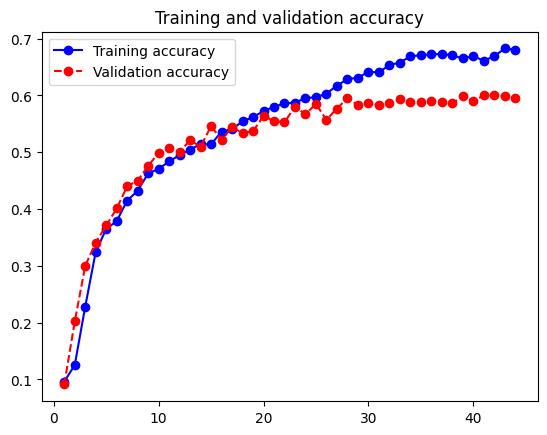

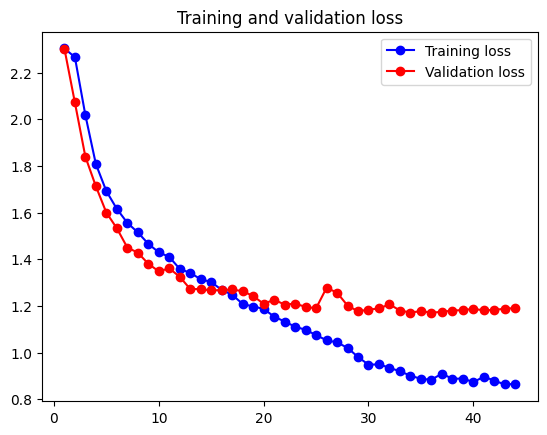

In [ ]:
plot(history11)

#### **Results**

To ensure a fair comparison, the architecture is based on that of Experiment 10, using the same number of filters but employing separable convolutions.

After reviewing the results, it can be seen that the parameter reduction introduced by the separable convolutions negatively impacted the model's learning capacity. While computationally lighter, the network struggles to capture the underlying patterns as effectively as its standard Inception counterpart. The training accuracy only manages to reach a 68.27% by epoch 43. The validation accuracy stabilizes at 60.00% (epochs 41-42), below the 62% benchmark established by our previous models and the lowest loss occurs at epoch 36 (1.1711) and then begins to plateau.

This final experiment again demonstrates that whether using deep sequential models, residual networks, parallel Inception paths, or attempting to force efficiency with Xception blocks, validation performance remains stuck at or below 62%. This shows that the limitation is inherent in training from scratch with small (96x96) and varied images. The dataset simply lacks the necessary scale to teach a model universal and highly robust visual features. Consequently, the custom architecture phase has concluded. 

# Tuneado (sección aparte)

## Simple mejorado (mejor modelo y reducir tamaño y parametros obteniendo los mismos resultados)

In [ ]:
from tensorflow.keras import layers
inputs = Input(shape=(96, 96, 3))

# Data augmentation
x = RandomFlip("horizontal", seed=seed)(inputs)
x = RandomRotation(0.1, seed=seed)(x)
x = RandomZoom(0.1, seed=seed)(x)

# Normalization
norm_layer = Normalization()
norm_layer.adapt(ds_train.map(lambda x, y: x))
x = norm_layer(x)

x = layers.SeparableConv2D(32, (5, 5), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.SeparableConv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.SeparableConv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)

x = layers.SeparableConv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)

x = layers.Flatten()(x)
cnn = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu')(cnn)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_tunned = keras.Model(inputs=inputs, outputs=outputs)

model_tunned.compile(optimizer='adam',
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

model_tunned.summary()

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_33 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_33 (RandomFlip)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_33              │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_33 (RandomZoom)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_32                │ (None, 96, 96, 3)      │             7 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_109            │ (None, 96, 96, 32)     │           203 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_146               │ (None, 48, 48, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_110            │ (None, 48, 48, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_147               │ (None, 24, 24, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_111            │ (None, 24, 24, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_148               │ (None, 8, 8, 128)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_112            │ (None, 8, 8, 256)      │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_149               │ (None, 2, 2, 256)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_28 (Flatten)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_60 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_61 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310,652 (1.19 MB)

 Trainable params: 310,645 (1.19 MB)

 Non-trainable params: 7 (32.00 B)

In [ ]:
reset_seeds()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_tunned = model_tunned.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])


Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.1115 - loss: 2.2891 - val_accuracy: 0.1690 - val_loss: 2.1775 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.2075 - loss: 2.0890 - val_accuracy: 0.2560 - val_loss: 1.9295 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.3013 - loss: 1.8461 - val_accuracy: 0.3500 - val_loss: 1.7080 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.3430 - loss: 1.7169 - val_accuracy: 0.3720 - val_loss: 1.6412 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.3775 - loss: 1.6447 - val_accuracy: 0.3970 - val_loss: 1.6087 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.4047 - loss: 1.5898 - val_accuracy: 0.4310 - val_loss: 1.5361 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.4193 - l

In [ ]:
plot(history_tunned)

# Testing finetuning

In [29]:
norm_layer_dc = layers.Normalization()
norm_layer_dc.adapt(ds_dogs_cats.map(lambda x, y: x))
inputs = layers.Input(shape=(96, 96, 3))
# Data augmentation

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1, fill_mode='reflect'),
    layers.RandomZoom(0.1, fill_mode='reflect')
])

x = data_augmentation(inputs)
# x = layers.Rescaling(1./255)(x)
x = norm_layer_dc(x)
x = layers.Conv2D(32, (5, 5), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)
# x = layers.Flatten()(x)
x = layers.GlobalAveragePooling2D()(x)
cnn = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(cnn)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(2, activation='softmax')(x)

model12 = keras.Model(inputs=inputs, outputs=outputs)

model12.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

model12.summary()

2026-03-11 10:44:36.383783: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_5 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 96, 96, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,113 (1.61 MB)

 Trainable params: 423,106 (1.61 MB)

 Non-trainable params: 7 (32.00 B)

In [25]:
norm_layer_dc = layers.Normalization()
norm_layer_dc.adapt(ds_dogs_cats.map(lambda x, y: x))
inputs = layers.Input(shape=(96, 96, 3))
# Data augmentation

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1, fill_mode='reflect'),
    layers.RandomZoom(0.1, fill_mode='reflect')
])

x = data_augmentation(inputs)
# x = layers.Rescaling(1./255)(x)
x = norm_layer_dc(x)
x = layers.SeparableConv2D(32, (5, 5), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.SeparableConv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.SeparableConv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)
x = layers.SeparableConv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((3, 3))(x)
# x = layers.Flatten()(x)
x = layers.GlobalAveragePooling2D()(x)
cnn = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(cnn)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(2, activation='softmax')(x)

model12 = keras.Model(inputs=inputs, outputs=outputs)

model12.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model12.summary()

2026-03-10 18:31:42.198369: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_4 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 96, 96, 32)     │           203 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 48, 48, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 24, 24, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 8, 8, 256)      │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,836 (307.96 KB)

 Trainable params: 78,829 (307.93 KB)

 Non-trainable params: 7 (32.00 B)

In [30]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="loss", mode="min", patience=3)
best_model_checkpoint = keras.callbacks.ModelCheckpoint(
    "best_model_cats_dogs.h5", monitor="loss", mode="min", save_best_only=True)
history12 = model12.fit(ds_dogs_cats,
                        epochs=100, callbacks=[best_model_checkpoint, early_stopping])


Epoch 1/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.5375 - loss: 0.6925

727/727 ━━━━━━━━━━━━━━━━━━━━ 48s 58ms/step - accuracy: 0.5851 - loss: 0.6668
Epoch 2/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6854 - loss: 0.6043

727/727 ━━━━━━━━━━━━━━━━━━━━ 43s 59ms/step - accuracy: 0.6946 - loss: 0.5920
Epoch 3/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7065 - loss: 0.5776

727/727 ━━━━━━━━━━━━━━━━━━━━ 53s 73ms/step - accuracy: 0.7171 - loss: 0.5671
Epoch 4/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7202 - loss: 0.5542

727/727 ━━━━━━━━━━━━━━━━━━━━ 41s 56ms/step - accuracy: 0.7328 - loss: 0.5443
Epoch 5/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7510 - loss: 0.5253

727/727 ━━━━━━━━━━━━━━━━━━━━ 41s 56ms/step - accuracy: 0.7509 - loss: 0.5238
Epoch 6/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7522 - loss: 0.5188

... (4 outputs left out)

727/727 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.7853 - loss: 0.4882
Epoch 12/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7921 - loss: 0.4925

727/727 ━━━━━━━━━━━━━━━━━━━━ 37s 51ms/step - accuracy: 0.7952 - loss: 0.4829
Epoch 13/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.7934 - loss: 0.4829
Epoch 14/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.7969 - loss: 0.4915
Epoch 15/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8017 - loss: 0.4699

727/727 ━━━━━━━━━━━━━━━━━━━━ 38s 52ms/step - accuracy: 0.8080 - loss: 0.4563
Epoch 16/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.8022 - loss: 0.4912
Epoch 17/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8115 - loss: 0.4608

727/727 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.8155 - loss: 0.4447
Epoch 18/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.8127 - loss: 0.4717
Epoch 19/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 36s 49ms/step - accuracy: 0.8160 - loss: 0.4604
Epoch 20/100
727/727 ━━━━━━━━━━━━━━━━━━━━ 40s 54ms/step - accuracy: 0.8161 - loss: 0.4631


In [33]:
# 1. Cargar modelo
best_model = keras.models.load_model("best_model_cats_dogs.h5")

for layer in best_model.layers:
    if isinstance(layer, layers.Normalization):
        layer.adapt(ds_train.map(lambda x, y: x))
        print(f"Adaptada normalización en capa: {layer.name}")

# 2. Congelar TODAS las capas primero
for layer in best_model.layers:
    layer.trainable = False

# 3. Descongelar las últimas 2 SeparableConv2D
# Buscar las capas SeparableConv2D y descongelar las últimas 2
sep_conv_layers = [layer for layer in best_model.layers
                   if isinstance(layer, layers.SeparableConv2D)]
for layer in sep_conv_layers[-2:]:
    layer.trainable = True
    print(f"Descongelada: {layer.name}")

# 4. Extraer la salida intermedia (capa dropout después de GAP)
# Buscar la capa por nombre o índice
cnn_output = None
for layer in best_model.layers:
    if isinstance(layer, layers.Dropout):
        cnn_output = layer
# Usar la salida del último Dropout antes de Dense (la capa 'cnn')

# 5. Construir nuevo modelo con cabeza para 10 clases
# Cortar el modelo en la capa dropout después de GAP
# Ajusta el índice según tu inspección
dropout_layer_output = best_model.layers[-4].output

x = layers.Dense(128, activation='relu')(dropout_layer_output)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_finetune = keras.Model(inputs=best_model.input, outputs=outputs)

# 6. Verificar qué capas son entrenables
for layer in model_finetune.layers:
    print(f"{layer.name}: trainable={layer.trainable}")

# 7. Compilar con learning rate bajo para fine-tuning
model_finetune.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4),  # LR bajo para fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_finetune.summary()

Adaptada normalización en capa: normalization_5
input_layer_7: trainable=False
sequential_2: trainable=False
normalization_5: trainable=False
conv2d_13: trainable=False
max_pooling2d_17: trainable=False
conv2d_14: trainable=False
max_pooling2d_18: trainable=False
conv2d_15: trainable=False
max_pooling2d_19: trainable=False
conv2d_16: trainable=False
max_pooling2d_20: trainable=False
global_average_pooling2d_1: trainable=False
dropout_16: trainable=False
dense_26: trainable=True
dropout_19: trainable=True
dense_27: trainable=True


2026-03-11 11:45:10.000737: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Model: "functional_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_5 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 96, 96, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,145 (1.62 MB)

 Trainable params: 34,186 (133.54 KB)

 Non-trainable params: 389,959 (1.49 MB)

In [31]:
best_model = keras.models.load_model("best_model_cats_dogs.h5")
# Modificar la normalización de best_model para que use la normalización adaptada a STL-10
for layer in best_model.layers:
    if isinstance(layer, layers.Normalization):
        layer.adapt(ds_train.map(lambda x, y: x))
        print(f"Adaptada normalización en capa: {layer.name}")
dropout_layer_output = best_model.layers[-4].output

x = layers.Dense(128, activation='relu')(dropout_layer_output)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_finetune = keras.Model(inputs=best_model.input, outputs=outputs)

model_finetune.compile(optimizer='adam',
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

model_finetune.summary()

2026-03-11 10:57:52.862687: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Adaptada normalización en capa: normalization_5


Model: "functional_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_5 (Normalization) │ (None, 96, 96, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 96, 96, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,145 (1.62 MB)

 Trainable params: 424,138 (1.62 MB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/100
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0958 - loss: 9.8885

125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.0975 - loss: 9.2390 - val_accuracy: 0.1220 - val_loss: 3.7037
Epoch 2/100
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1100 - loss: 8.3109

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.1173 - loss: 7.9491 - val_accuracy: 0.1640 - val_loss: 3.2744
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1205 - loss: 7.5726

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.1260 - loss: 7.4368 - val_accuracy: 0.1860 - val_loss: 2.9225
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1411 - loss: 6.9090

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.1373 - loss: 6.9825 - val_accuracy: 0.2100 - val_loss: 2.8165
Epoch 5/100
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1482 - loss: 6.5489

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.1392 - loss: 6.6678 - val_accuracy: 0.2220 - val_loss: 2.6574
Epoch 6/100
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1438 - loss: 6.4380

... (39 outputs left out)

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2480 - loss: 2.2331 - val_accuracy: 0.3420 - val_loss: 1.8790
Epoch 86/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2527 - loss: 2.1897

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2403 - loss: 2.2243 - val_accuracy: 0.3370 - val_loss: 1.8789
Epoch 87/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2418 - loss: 2.2269 - val_accuracy: 0.3380 - val_loss: 1.8869
Epoch 88/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2428 - loss: 2.1947

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2400 - loss: 2.2019 - val_accuracy: 0.3450 - val_loss: 1.8685
Epoch 89/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2400 - loss: 2.1768 - val_accuracy: 0.3480 - val_loss: 1.8799
Epoch 90/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2435 - loss: 2.1743 - val_accuracy: 0.3430 - val_loss: 1.8797
Epoch 91/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2522 - loss: 2.1374 - val_accuracy: 0.3480 - val_loss: 1.8895
Epoch 92/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2508 - loss: 2.1267 - val_accuracy: 0.3440 - val_loss: 1.8856
Epoch 93/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.2495 - loss: 2.1370 - val_accuracy: 0.3360 - val_loss: 1.8782
Epoch 94/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.2548 - loss: 2.1003 - val_accuracy: 0.3410 - val_loss: 1.8762
Epoch 95/100
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2678 - loss: 2.0320

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.2555 - loss: 2.0740 - val_accuracy: 0.3470 - val_loss: 1.8660
Epoch 96/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.2548 - loss: 2.0992 - val_accuracy: 0.3470 - val_loss: 1.8800
Epoch 97/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.2573 - loss: 2.0583 - val_accuracy: 0.3410 - val_loss: 1.8748
Epoch 98/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2598 - loss: 2.0630 - val_accuracy: 0.3540 - val_loss: 1.8676
Epoch 99/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2645 - loss: 2.0615 - val_accuracy: 0.3430 - val_loss: 1.8836
Epoch 100/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2668 - loss: 2.0376 - val_accuracy: 0.3590 - val_loss: 1.8708


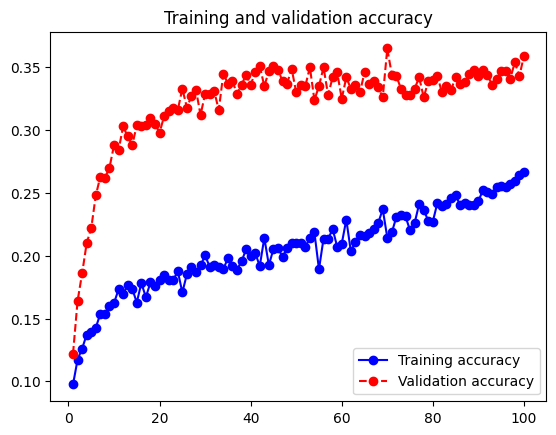

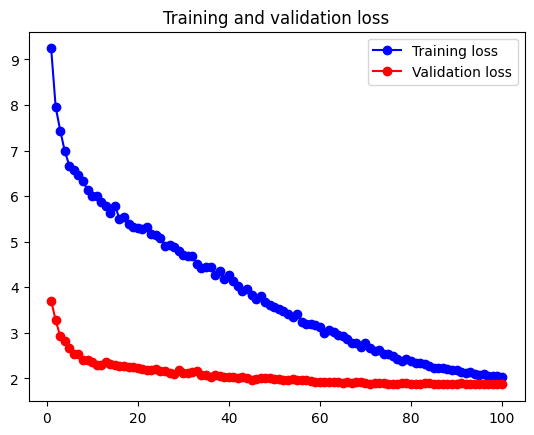

In [34]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10)
best_model_checkpoint = keras.callbacks.ModelCheckpoint(
    "best_model.h5", monitor="val_loss", mode="min", save_best_only=True)
history13 = model_finetune.fit(ds_train, validation_data=ds_val,
                      epochs=100, callbacks=[ best_model_checkpoint, early_stopping])

plot(history13)

In [1]:
# Ver si los gradientes explotan en la primera época
import tensorflow as tf

for images, labels in ds_train_.take(1):
    with tf.GradientTape() as tape:
        preds = model12(images, training=True)
        loss = tf.keras.losses.categorical_crossentropy(labels, preds)
    grads = tape.gradient(loss, model12.trainable_variables)
    for g, v in zip(grads, model12.trainable_variables):
        if g is not None:
            print(f"{v.name}: grad_norm={tf.norm(g).numpy():.4f}")

KeyboardInterrupt: 

NameError: name 'ds_train_' is not defined

## Testing

In [87]:
inception_model = keras.Model(inputs=inputs, outputs=inception)
# Opción 1: Tomar un batch de ejemplo
for images, labels in ds_test.take(1):
    inception_output = inception_model.predict(images)
    print("Shape del output:", inception_output.shape)
    print("Min/Max valores:", inception_output.min(), inception_output.max())
    print(inception_output)

# Save the inception output in a readable format (e.g., CSV)
import pandas as pd
inception_output_df = pd.DataFrame(inception_output.reshape(inception_output.shape[0], -1))
inception_output_df.to_csv("inception_output.csv", index=False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step
Shape del output: (32, 47, 47, 224)
Min/Max valores: 0.0 0.9970041
[[[[0.01343428 0.         0.         ... 0.         0.
    0.0196511 ]
   [0.01484717 0.         0.         ... 0.         0.
    0.01861835]
   [0.01285909 0.         0.         ... 0.         0.
    0.01858058]
   ...
   [0.         0.         0.         ... 0.         0.
    0.02935116]
   [0.         0.         0.         ... 0.         0.
    0.03184276]
   [0.         0.         0.         ... 0.         0.
    0.03300759]]

  [[0.00576599 0.         0.         ... 0.         0.
    0.01923133]
   [0.0025167  0.         0.         ... 0.         0.
    0.01804024]
   [0.00109235 0.         0.         ... 0.         0.
    0.01858058]
   ...
   [0.         0.         0.         ... 0.         0.
    0.02696755]
   [0.00072232 0.         0.         ... 0.         0.
    0.03047279]
   [0.00030097 0.         0.         ... 0.         0.
    0.03227819]]

  [[0.00351815 0.       

2026-03-05 19:37:23.074348: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## Pretrained Models
From now on, we will employ a new pipeline. For each pretrained model, we will evaluate three training strategies:

1. **Full Fine-tuning**: Train all model parameters with a low learning rate
2. **Partial Fine-tuning**: Train only the last layers while freezing earlier layers
3. **Feature Extraction**: Freeze the backbone and train only the dense head layers

For each model, we will start with partial fine-tuning and feature extraction to assess performance. If partial fine-tuning outperforms feature extraction, we will then proceed with full fine-tuning. This staged approach is necessary because full fine-tuning is computationally expensive and resource-intensive.

In [ ]:
import tensorflow as tf
from keras import layers, models

def get_preprocess_input(base_model_class):
    name = base_model_class.__name__.lower()
    if "inceptionresnetv2" in name:
        from keras.applications.inception_resnet_v2 import preprocess_input
        return preprocess_input
    if "efficientnet" in name:
        from keras.applications.efficientnet import preprocess_input
        return preprocess_input
    if "convnext" in name:
        from keras.applications.convnext import preprocess_input
        return preprocess_input
    return None

def build_transfer_model(
    base_model_class,
    input_shape=(224, 224, 3),
    num_classes=10,
    mode="frozen",
    last_n_trainable=0,
    dense_units=(256,),
    dropout_rate=0.3,
    weights="imagenet",
    freeze_batchnorm=True,
    adaptation_data=None,
    force_cpu_backbone=False
    ):
    use_cpu_backbone = force_cpu_backbone

    if use_cpu_backbone:
        with tf.device("/CPU:0"):
            base_model = base_model_class(include_top=False, weights=weights, input_shape=input_shape)
    else:
        base_model = base_model_class(include_top=False, weights=weights, input_shape=input_shape)

    if mode == "frozen":
        base_model.trainable = False
    elif mode == "full":
        base_model.trainable = True
    elif mode == "partial":
        base_model.trainable = True
        for layer in base_model.layers[:-last_n_trainable]:
            layer.trainable = False
    else:
        raise ValueError("mode must be 'frozen', 'partial' or 'full'")

    if freeze_batchnorm and mode in ("partial", "full"):
        for layer in base_model.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

    inputs = keras.Input(shape=input_shape)

    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1, fill_mode='reflect'),
        layers.RandomZoom(0.1, fill_mode='reflect')
    ])
    x = data_augmentation(inputs)

    preprocess_input = get_preprocess_input(base_model_class)
    if preprocess_input is not None:
        x = layers.Lambda(preprocess_input, name=f"{base_model_class.__name__.lower()}_preprocess")(x)
    elif adaptation_data is not None:
        norm_layer = layers.Normalization()
        norm_layer.adapt(adaptation_data)
        x = norm_layer(x)
    else:
        x = layers.Rescaling(1./255)(x)

    backbone_training = mode == "full" and not freeze_batchnorm
    if use_cpu_backbone:
        with tf.device("/CPU:0"):
            x = base_model(x, training=backbone_training)
    else:
        x = base_model(x, training=backbone_training)

    x = layers.GlobalAveragePooling2D()(x)
    for units in dense_units:
        x = layers.Dense(units, activation="relu")(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)

    activation = "sigmoid" if num_classes == 1 else "softmax"
    outputs = layers.Dense(num_classes, activation=activation)(x)

    return keras.Model(inputs, outputs)

### Inception ResNetV2

As mentioned before we will test the architecture by partially tuning and doing feature extraction. If the difference between the both is not significant we won't train the full network as it would require significant computational effort for just a small improve in accuracy.

#### Partial Tuning

The first thing to do is to import the model and pass it to the function, we will also configure the input shape and the output shape as well as we will set the mode to partial. We decided to pick the last 20 layers trainable as the depth of the network is 449 and we want to finetune 5% approximately of the hole network. Two are arguments that supports this decision:

1. By tuning only the last layers we are adapting the more abstract layers, those convolutions that in theory allows to detect the concepts being classified.
2. Tunning the last layers allows to reduce the computational cost of the training process as we will only do the forward pass for 95% of the network. Which allows us to train them localy.

In [ ]:
from keras.applications import InceptionResNetV2
inception_partial = build_transfer_model(
    base_model_class=InceptionResNetV2,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="partial",
    last_n_trainable=20,
    freeze_batchnorm=True
)
inception_partial.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 37s 135ms/step - accuracy: 0.2702 - loss: 2.8469 - val_accuracy: 0.6330 - val_loss: 1.1836 - learning_rate: 1.0000e-05
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.5235 - loss: 1.5852 - val_accuracy: 0.7230 - val_loss: 0.8368 - learning_rate: 1.0000e-05
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 99ms/step - accuracy: 0.5925 - loss: 1.3000 - val_accuracy: 0.7540 - val_loss: 0.7256 - learning_rate: 1.0000e-05
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - accuracy: 0.6543 - loss: 1.1275 - val_accuracy: 0.7790 - val_loss: 0.6582 - learning_rate: 1.0000e-05
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.6750 - loss: 1.0218 - val_accuracy: 0.7920 - val_loss: 0.6251 - learning_rate: 1.0000e-05
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.6940 - loss: 0.9271 - val_accuracy: 0.8090 - val_loss: 0.5991 - learning_rate: 1.0000e-05
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step

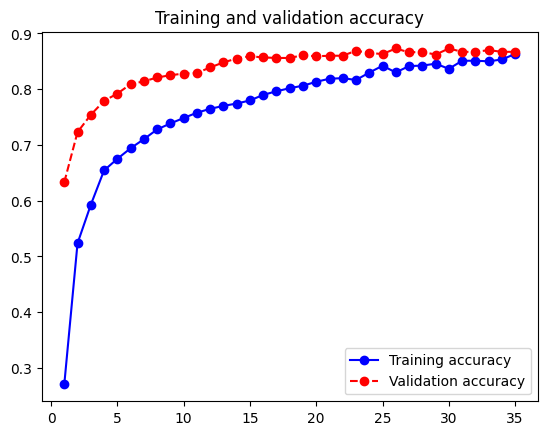

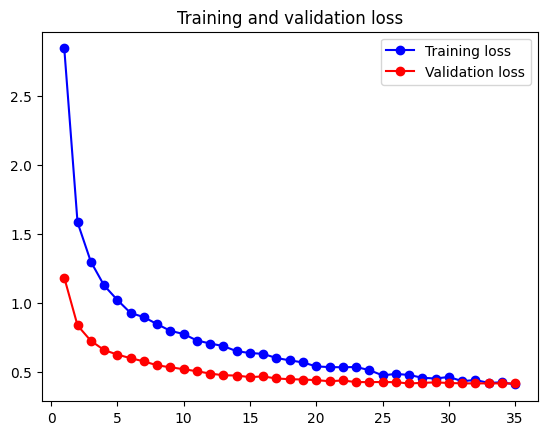

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = inception_partial.fit(
    ds_train,
    validation_data=ds_val,
    epochs=80,
    callbacks=[early_stopping, reduce_lr]
 )

plot(history)

The results from the tuning shows the best accuracy and loss till now. Our next step will be to repeat the process but with feature extraction.

#### Feature extractor

In this section we will set the model parameters in not training mode, so we will only adapt the last feed forward layers. 

In [ ]:
inception_feature_extract = build_transfer_model(
    base_model_class=InceptionResNetV2,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="frozen"
)
inception_feature_extract.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - accuracy: 0.6285 - loss: 1.2639 - val_accuracy: 0.8080 - val_loss: 0.5984 - learning_rate: 0.0010
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7160 - loss: 0.8553 - val_accuracy: 0.8200 - val_loss: 0.5444 - learning_rate: 0.0010
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.7228 - loss: 0.7738 - val_accuracy: 0.8210 - val_loss: 0.5310 - learning_rate: 0.0010
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.7565 - loss: 0.6990 - val_accuracy: 0.8390 - val_loss: 0.5084 - learning_rate: 0.0010
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.7655 - loss: 0.6849 - val_accuracy: 0.8460 - val_loss: 0.4939 - learning_rate: 0.0010
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.7797 - loss: 0.6351 - val_accuracy: 0.8400 - val_loss: 0.4861 - learning_rate: 0.0010
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7725 -

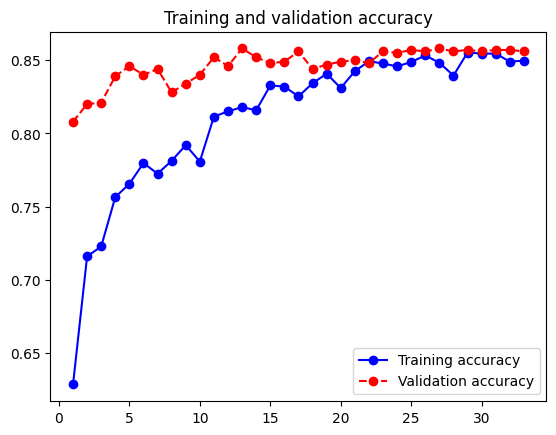

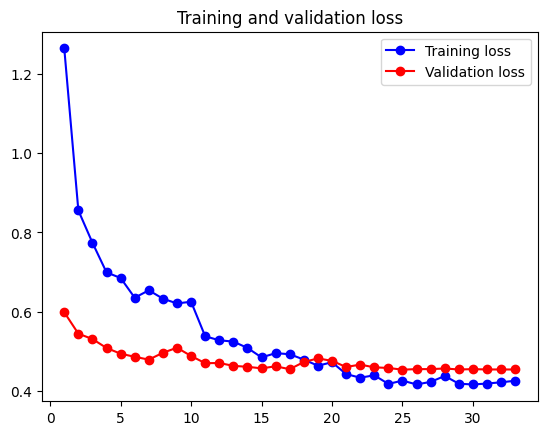

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = inception_feature_extract.fit(ds_train, validation_data=ds_val,
                    epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

Given that both networks perform similarly and there is not a great improvement when tuning part of the network we won't train the full model.

### EfficientNetB4

Prior architectures scaled networks by arbitrarily increasing, depth (more layers), width (more channels) and Resolution (larger input images). These dimensions were scaled independently and without a principled method.

EfficientNet, introduced by Google in 2019, brought a key innovation: **compound scaling**. The idea proposed was scaling all three dimensions **simultaneously** using a fixed compound coefficient **φ**:

- **Depth**: $d = α^φ$
- **Width**: $w = β^φ$
- **Resolution**: $r = γ^φ$

Subject to the constraint: $α · β² · γ² ≈ 2$, so that FLOPS roughly double for each step in φ.

Thanks to this EfficientNet achieves **better accuracy with fewer parameters** than previous architectures like ResNet or Inception, making it both more accurate and more efficient.

In this section as in the previous we will test both feature extraction and partial tuning and if a significant difference is found in the performance we will also train the full network.

#### Partial Tuning

In [ ]:
from keras.applications import EfficientNetB4

efficient_partial = build_transfer_model(
    base_model_class=EfficientNetB4,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="partial",
    last_n_trainable=15
)
efficient_partial.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 145ms/step - accuracy: 0.6143 - loss: 1.2247 - val_accuracy: 0.8590 - val_loss: 0.5036 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.7667 - loss: 0.7542 - val_accuracy: 0.8690 - val_loss: 0.4386 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.7905 - loss: 0.6289 - val_accuracy: 0.8770 - val_loss: 0.3986 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.8087 - loss: 0.5747 - val_accuracy: 0.8790 - val_loss: 0.3762 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.8310 - loss: 0.5170 - val_accuracy: 0.8820 - val_loss: 0.3680 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.8385 - loss: 0.4849 - val_accuracy: 0.8840 - val_loss: 0.3481 - learning_rate: 1.0000e-04
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/s

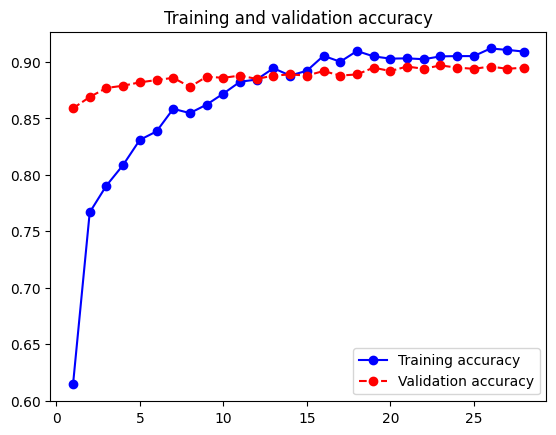

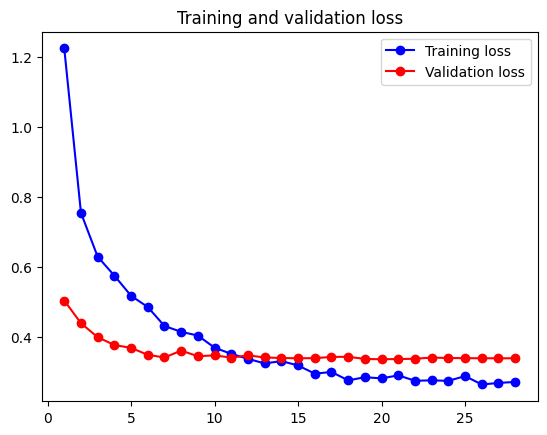

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = efficient_partial.fit(ds_train, validation_data=ds_val,
                                epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

#### Feature extractor

In [14]:
efficient_feature_extract = build_transfer_model(
    base_model_class=EfficientNetB4,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="frozen"
)
efficient_feature_extract.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 34s 100ms/step - accuracy: 0.5242 - loss: 1.5790 - val_accuracy: 0.8210 - val_loss: 0.8842 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.7387 - loss: 0.8881 - val_accuracy: 0.8660 - val_loss: 0.5712 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.7760 - loss: 0.7218 - val_accuracy: 0.8700 - val_loss: 0.4850 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7795 - loss: 0.6668 - val_accuracy: 0.8740 - val_loss: 0.4466 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.7905 - loss: 0.6205 - val_accuracy: 0.8820 - val_loss: 0.4234 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.8060 - loss: 0.5766 - val_accuracy: 0.8860 - val_loss: 0.4074 - learning_rate: 1.0000e-04
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/s

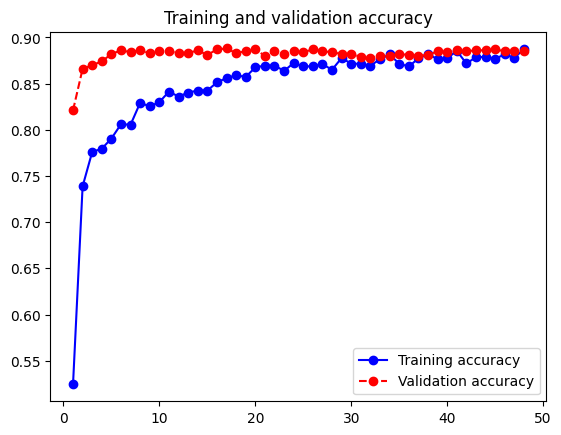

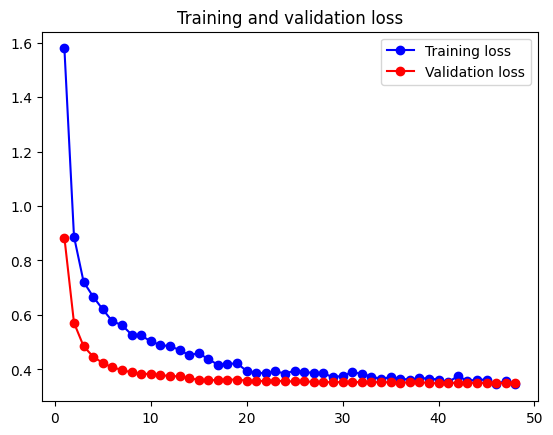

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = efficient_feature_extract.fit(ds_train, validation_data=ds_val,
                                        epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

This new network demonstrate to outperform Inception on its performance, proving what was proposed in theory before. Besides we find the same pattern as with inception, tuning the network shows an slight performance upgrade but not enough to justify the training of the full network.

### ConvNeXtBase
ConvNeXt, introduced by Meta AI in 2022, modernized the classic ResNet architecture by incorporating design choices inspired by Vision Transformers (ViT), while remaining a pure convolutional network. Its key contributions to the community are listed below:

- Training recipe modernization: Adopted improved training techniques from the Transformer era (AdamW optimizer, cosine schedule, longer training, strong augmentations).
- Macro design improvements: Adjusted stage compute ratios and adopted a patchify stem (4×4 non-overlapping convolutions), similar to ViT.
- Depthwise separable convolutions: Replaced standard 3×3 convolutions with depthwise 7×7 convolutions, increasing the receptive field while keeping computational cost low.
- Inverted bottleneck: Borrowed from MobileNetV2, expanding the hidden dimension in the MLP block (similar to Transformers' FFN).
- Replaced BatchNorm with LayerNorm: Demonstrated that LayerNorm, typically used in Transformers, also improves CNN performance.
- GELU activation: Replaced ReLU with GELU, widely used in Transformers.

The key takeaway was that a pure CNN, when modernized with Transformer-inspired design choices, can match or outperform Vision Transformers on standard benchmarks like ImageNet, while being simpler to train and deploy.

We will train 2 versions of ConvNext the ConvNextBase and ConvNextTiny, for the first we wil train only partial and with feature extraction will for the second we will try with the full training. Our idea is that this networks should be the best ones on the notebook so we will take the smaller of them and try in practice the impact of fully tuning the network. 

#### Partial Tuning

In [ ]:
from keras.applications import ConvNeXtBase

convnext_base_partial = build_transfer_model(
    base_model_class=ConvNeXtBase,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="partial",
    last_n_trainable=50,
 )
convnext_base_partial.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

350926856/350926856 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 129s 801ms/step - accuracy: 0.8830 - loss: 0.3973 - val_accuracy: 0.9870 - val_loss: 0.0533 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 664ms/step - accuracy: 0.9725 - loss: 0.0922 - val_accuracy: 0.9880 - val_loss: 0.0558 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 663ms/step - accuracy: 0.9812 - loss: 0.0588 - val_accuracy: 0.9910 - val_loss: 0.0479 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 657ms/step - accuracy: 0.9852 - loss: 0.0419 - val_accuracy: 0.9860 - val_loss: 0.0547 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 653ms/step - accuracy: 0.9875 - loss: 0.0365 - val_accuracy: 0.9890 - val_loss: 0.0575 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 587ms/step - accuracy: 0.9879 - loss: 0.0408
Epoch 6: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 

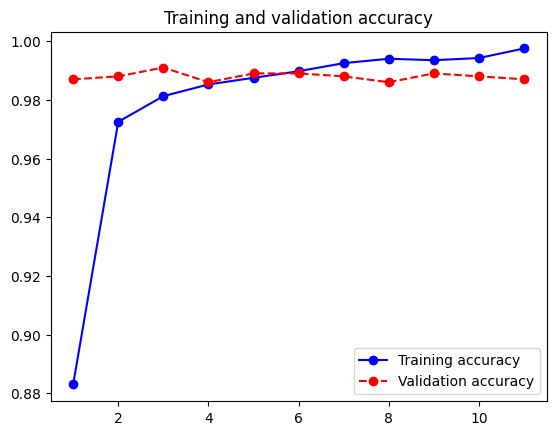

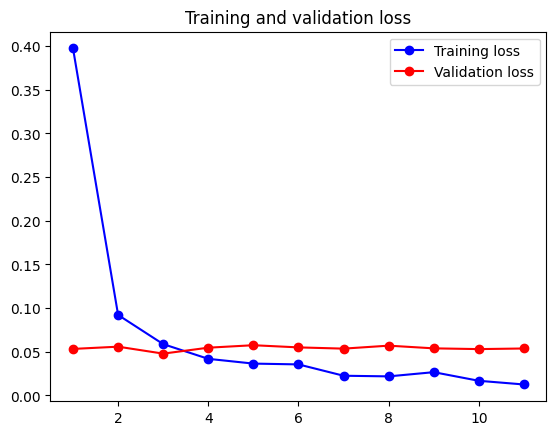

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = convnext_base_partial.fit(ds_train, validation_data=ds_val,
                                        epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

#### Feature extractor

In [ ]:
convnext_base_feature_extract = build_transfer_model(
    base_model_class=ConvNeXtBase,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="frozen")
convnext_base_feature_extract.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 492ms/step - accuracy: 0.7030 - loss: 1.0158 - val_accuracy: 0.9540 - val_loss: 0.3245 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 46s 365ms/step - accuracy: 0.9310 - loss: 0.2862 - val_accuracy: 0.9770 - val_loss: 0.1605 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 44s 350ms/step - accuracy: 0.9460 - loss: 0.1974 - val_accuracy: 0.9830 - val_loss: 0.1142 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 360ms/step - accuracy: 0.9538 - loss: 0.1596 - val_accuracy: 0.9860 - val_loss: 0.0916 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 44s 353ms/step - accuracy: 0.9600 - loss: 0.1392 - val_accuracy: 0.9860 - val_loss: 0.0784 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 357ms/step - accuracy: 0.9647 - loss: 0.1218 - val_accuracy: 0.9870 - val_loss: 0.0706 - learning_rate: 1.0000e-04
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━

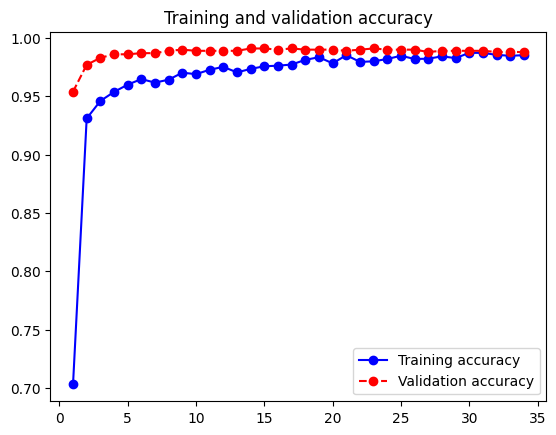

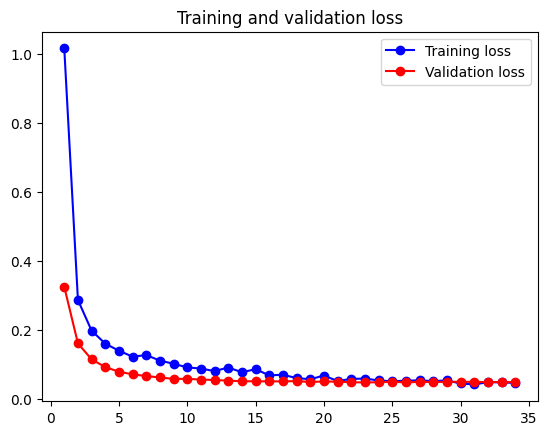

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = convnext_base_feature_extract.fit(ds_train, validation_data=ds_val,
                                                epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

As with EfficientNet ConvNeXt showed to be a new step forward on CNN. It outperforms by a gap all previous networks showing stuning performance upgrades.

### ConvNeXtTiny

As mention in the previous section we will test with this network to do a full tune and compare its performance with the other two options of tuning.

#### Full Tuning

In [ ]:
from keras.applications import ConvNeXtTiny
convnext_tiny_full = build_transfer_model(
    base_model_class=ConvNeXtTiny,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="full",
 )
convnext_tiny_full.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 95s 458ms/step - accuracy: 0.7423 - loss: 0.8552 - val_accuracy: 0.9480 - val_loss: 0.1925 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 49s 389ms/step - accuracy: 0.9427 - loss: 0.1896 - val_accuracy: 0.9680 - val_loss: 0.1276 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 50s 399ms/step - accuracy: 0.9725 - loss: 0.0988 - val_accuracy: 0.9650 - val_loss: 0.1368 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 51s 406ms/step - accuracy: 0.9805 - loss: 0.0634 - val_accuracy: 0.9650 - val_loss: 0.1391 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step - accuracy: 0.9879 - loss: 0.0431
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
125/125 ━━━━━━━━━━━━━━━━━━━━ 51s 412ms/step - accuracy: 0.9877 - loss: 0.0439 - val_accuracy: 0.9650 - val_loss: 0.1353 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 52s 4

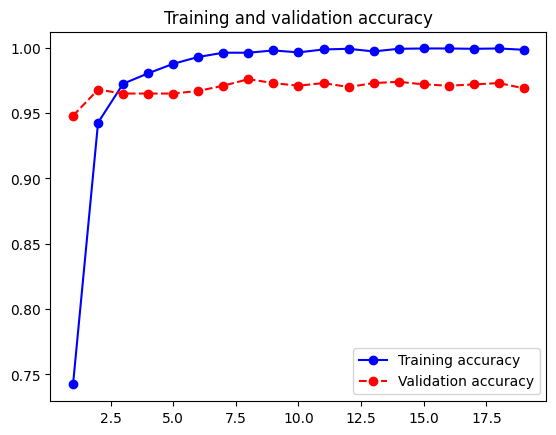

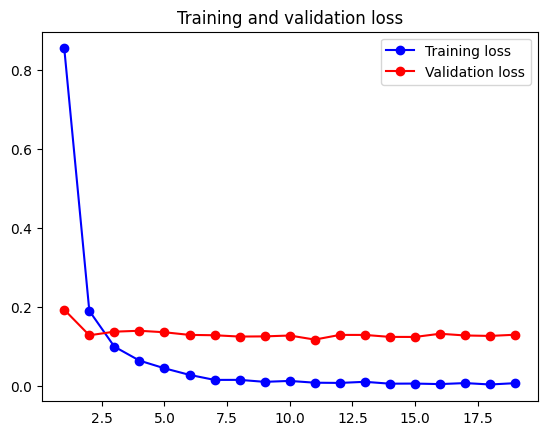

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = convnext_tiny_full.fit(ds_train, validation_data=ds_val,
                                  epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

#### Partial Tuning

In [ ]:
convnext_tiny_partial = build_transfer_model(
    base_model_class=ConvNeXtTiny,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="partial",
    last_n_trainable=15,
 )
convnext_tiny_partial.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 42s 221ms/step - accuracy: 0.6560 - loss: 1.1079 - val_accuracy: 0.9420 - val_loss: 0.2714 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 170ms/step - accuracy: 0.9137 - loss: 0.2990 - val_accuracy: 0.9570 - val_loss: 0.1565 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 162ms/step - accuracy: 0.9390 - loss: 0.2019 - val_accuracy: 0.9610 - val_loss: 0.1341 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.9477 - loss: 0.1753 - val_accuracy: 0.9580 - val_loss: 0.1279 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 160ms/step - accuracy: 0.9575 - loss: 0.1326 - val_accuracy: 0.9640 - val_loss: 0.1275 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 163ms/step - accuracy: 0.9660 - loss: 0.1093 - val_accuracy: 0.9600 - val_loss: 0.1269 - learning_rate: 1.0000e-04
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━

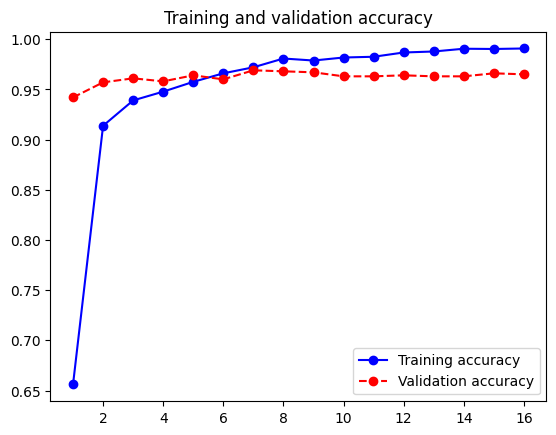

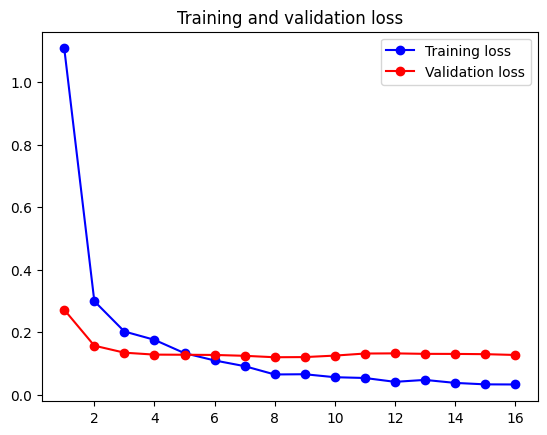

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = convnext_tiny_partial.fit(ds_train, validation_data=ds_val,
                                        epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

#### Feature extractor

In [ ]:
convnext_tiny_feature_extract = build_transfer_model(
    base_model_class=ConvNeXtTiny,
    input_shape=(96, 96, 3),
    num_classes=10,
    mode="frozen")
convnext_tiny_feature_extract.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
 )

Epoch 1/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 30s 157ms/step - accuracy: 0.5263 - loss: 1.5133 - val_accuracy: 0.8520 - val_loss: 0.6810 - learning_rate: 1.0000e-04
Epoch 2/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.8160 - loss: 0.6946 - val_accuracy: 0.9170 - val_loss: 0.3962 - learning_rate: 1.0000e-04
Epoch 3/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 103ms/step - accuracy: 0.8725 - loss: 0.4899 - val_accuracy: 0.9370 - val_loss: 0.2957 - learning_rate: 1.0000e-04
Epoch 4/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.8855 - loss: 0.4096 - val_accuracy: 0.9410 - val_loss: 0.2473 - learning_rate: 1.0000e-04
Epoch 5/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.8932 - loss: 0.3643 - val_accuracy: 0.9440 - val_loss: 0.2186 - learning_rate: 1.0000e-04
Epoch 6/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.9038 - loss: 0.3179 - val_accuracy: 0.9480 - val_loss: 0.1999 - learning_rate: 1.0000e-04
Epoch 7/400
125/125 ━━━━━━━━━━━━━━━━━━━━ 1

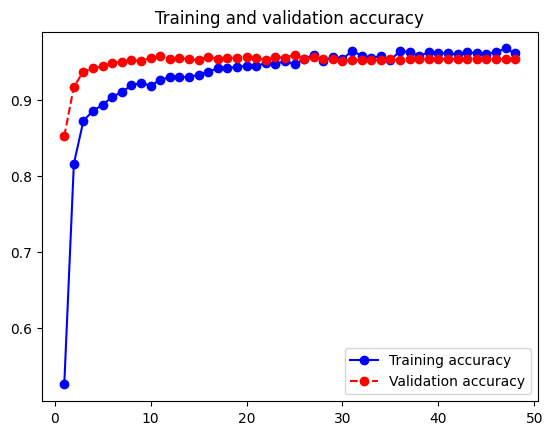

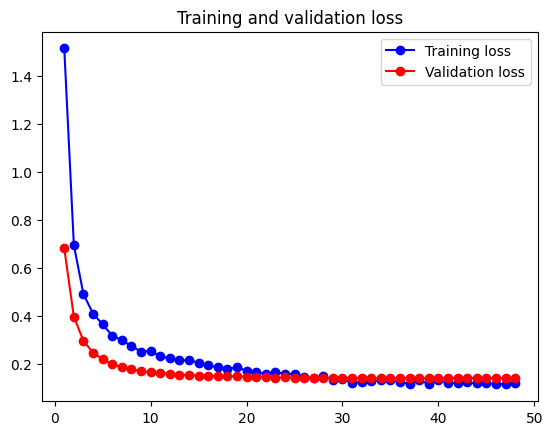

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)
history = convnext_tiny_feature_extract.fit(ds_train, validation_data=ds_val,
                                              epochs=400, callbacks=[early_stopping, reduce_lr])

plot(history)

It is quite relevant to see that the performance gain optained by tuning all the network against only the last layers is negligible. Despite it has been demonstrated that doing a partial tuning outperforms doing feature extraction; it is not so clear that there is a significant gain from tuning the whole network over doing a partial tuning.

### Evaluating with Test Datasets

In this section we will evaluate all the models trained against the test dataset to make some final conclusions.

In [ ]:
# Testing partial fine-tuned models
test_loss, test_acc = inception_partial.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = efficient_partial.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = convnext_base_partial.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = convnext_tiny_partial.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.8509 - loss: 0.4373
Test Loss: 0.4373, Test Accuracy: 0.8509
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8984 - loss: 0.2969
Test Loss: 0.2969, Test Accuracy: 0.8984
250/250 ━━━━━━━━━━━━━━━━━━━━ 71s 282ms/step - accuracy: 0.9884 - loss: 0.0411
Test Loss: 0.0411, Test Accuracy: 0.9884
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.9696 - loss: 0.0959
Test Loss: 0.0959, Test Accuracy: 0.9696


In [ ]:
# Testing feature extraction models
test_loss, test_acc = inception_feature_extract.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = efficient_feature_extract.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = convnext_base_feature_extract.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

test_loss, test_acc = convnext_tiny_feature_extract.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.8516 - loss: 0.4447
Test Loss: 0.4447, Test Accuracy: 0.8516
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.8915 - loss: 0.3169
Test Loss: 0.3169, Test Accuracy: 0.8915
250/250 ━━━━━━━━━━━━━━━━━━━━ 70s 280ms/step - accuracy: 0.9889 - loss: 0.0417
Test Loss: 0.0417, Test Accuracy: 0.9889
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 76ms/step - accuracy: 0.9656 - loss: 0.1089
Test Loss: 0.1089, Test Accuracy: 0.9656


In [ ]:
test_loss, test_acc = convnext_tiny_full.evaluate(ds_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")


250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.9696 - loss: 0.1094
Test Loss: 0.1094, Test Accuracy: 0.9696


As previously seen the final podium of the best pretrained models is:

1. ConvNextBase
2. ConvNextTiny
3. EfficientNet

Another relevant fact is that the full training in ConvNextTiny underperform compared with the partial tuning when compare with the test loss. The reason for this is probably that this networks are already trained with big and diverse datasets so their less abstract layers are properly trained. In this way you can find an improvement by training part of the network as it adapts the abstract concepts to our problem, but the same is not a significant improve from training the full network.